# 0. Load dữ liệu

- load `station_hour.csv` vào `df`
- load `stations.csv` vào `df_stations`

In [ ]:
%pip install --upgrade nbformat ipywidgets

In [ ]:
# load
PATH = '../data/raw/'

import pandas as pd
from pathlib import Path

# https://cpcb.gov.in/openpdffile.php?id=TGF0ZXN0RmlsZS8yNjRfMTU2NTI1Nzg1OV9tZWRpYXBob3RvMTU0MDcucGRm
df = pd.read_csv(
    PATH + "station_hour.csv",
    parse_dates=["Datetime"] # Nhớ parse date để tránh lag nếu vẽ đồ thị có date mà chưa parse
)
df_raw = df.copy()
print("station_hour.csv")
print([col for col in df.columns])
print()

print("stations.csv")
df_stations = pd.read_csv(PATH + "stations.csv")
print([col for col in df_stations.columns])

## 3. Cleanning

### 3.1. Kiểm tra tổng thể

In [ ]:
import pandas as pd
# Các cột cần kiểm tra
pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
    'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene'
]
numeric_cols = [c for c in pollutants + ['AQI'] if c in df.columns]
n = len(df)
# 1. Trùng toàn bộ dòng: đếm các dòng trùng dư, không tính lần xuất hiện đầu
duplicate_rows = int(df.duplicated().sum())
# 2. Datetime không hợp lệ
dt_parsed = pd.to_datetime(df['Datetime'], errors='coerce')
invalid_datetime = (
    df['Datetime'].notna() & dt_parsed.isna()
)
invalid_datetime_count = int(invalid_datetime.sum())
# 3. Trùng thời gian trong cùng trạm
station_key = df['StationId'].astype('string').str.strip()
valid_pair = (
    station_key.notna()
    & station_key.ne('')
    & dt_parsed.notna()
)
pairs = pd.DataFrame({
    'StationId': station_key.loc[valid_pair],
    'Datetime': dt_parsed.loc[valid_pair]
})
duplicate_datetime = int(
    pairs.duplicated(['StationId', 'Datetime']).sum()
)
# 4. Các ô không chuyển được sang kiểu số

invalid_numeric = pd.DataFrame(index=df.index)
for col in numeric_cols:
    converted = pd.to_numeric(df[col], errors='coerce')
    invalid_numeric[col] = df[col].notna() & converted.isna()
invalid_numeric_count = int(invalid_numeric.sum().sum())
# 5. StationId không tồn tại trong df_stations
valid_station_ids = (
    df_stations['StationId']
    .astype('string')
    .str.strip()
    .dropna()
)
invalid_station = (
    station_key.isna()
    | station_key.eq('')
    | ~station_key.isin(valid_station_ids)
).fillna(True)
invalid_station_count = int(invalid_station.sum())
# 6. Số lượng và tỷ lệ dữ liệu thiếu
missing_count = int(df.isnull().sum().sum())
missing_total = int(df.size)
# 7. Lập bảng tổng hợp
checks = [
    ('Trùng toàn bộ dòng', duplicate_rows, n),
    ('Trùng StationId + Datetime', duplicate_datetime, n),
    ('StationId không thuộc df_stations', invalid_station_count, n),
    ('Ô Datetime sai định dạng', invalid_datetime_count, n),
    (
        'Ô cột số không chuyển được sang numeric',
        invalid_numeric_count,
        n * len(numeric_cols)
    ),
    (
        'Tổng ô sai kiểu dữ liệu',
        invalid_datetime_count + invalid_numeric_count,
        n * (1 + len(numeric_cols))
    ),
    ('Dữ liệu thiếu', missing_count, missing_total)
]
summary = pd.DataFrame(
    checks,
    columns=['Vấn đề', 'Số lượng', 'Mẫu số tính tỷ lệ']
)
# Tính tỷ lệ phần trăm
summary['Tỷ lệ (%)'] = (
    summary['Số lượng']
    .div(summary['Mẫu số tính tỷ lệ'].replace(0, pd.NA))
    .mul(100)
    .round(3)
)
# Hiển thị bảng kết quả
display(summary)

#### Nhận xét : Qua bước đầu kiểm tra, dữ liệu có tỉ lệ sạch cao, ít bị các lỗi về định dạng,và thông tin. Tuy nhiên vẫn có tỷ lệ thiếu dữ liệu lên đến 28%

### 3.2 Một số thao tác làm sạch

#### 3.2.1. giá trị trần
- Giá trị trần gần với khoảng giới hạn đo của máy, [theo như tài liệu (trang 18-19)](https://cpcb.gov.in/openpdffile.php?id=TGF0ZXN0RmlsZS8yNjRfMTU2NTI1Nzg1OV9tZWRpYXBob3RvMTU0MDcucGRm)

In [ ]:
# Các giá trị cao xuất hiện nhiều bất thường ơ PM2.5 và PM10
import matplotlib.pyplot as plt

top_pm10 = df[df['PM10'] >= 900]['PM10'].value_counts().head(10)
display(top_pm10)
print()

# plt.figure(figsize=(8, 4))
# top_pm10.plot(kind='bar', color='crimson', edgecolor='black')
# plt.title('Tần suất xuất hiện của các giá trị cực trị (>= 900)', fontsize=13)
# plt.xlabel('Giá trị PM10', fontsize=11)
# plt.ylabel('Số lần xuất hiện', fontsize=11)
# plt.xticks(rotation=45)
# plt.grid(axis='y', linestyle='--', alpha=0.7)
# plt.show()

# Lọc các giá trị cao và đếm top giá trị xuất hiện nhiều nhất
top_pm25 = df[df['PM2.5'] >= 900]['PM2.5'].value_counts().head(10)
display(top_pm25)
print()


# plt.figure(figsize=(8, 4))
# top_pm25.plot(kind='bar', color='crimson', edgecolor='black')
# plt.title('Tần suất xuất hiện của các giá trị cực trị (>= 900)', fontsize=13)
# plt.xlabel('Giá trị PM2.5', fontsize=11)
# plt.ylabel('Số lần xuất hiện', fontsize=11)
# plt.xticks(rotation=45)
# plt.grid(axis='y', linestyle='--', alpha=0.7)
# plt.show()

In [ ]:
def show_mask_rate(mask, df, cols):
    summary = pd.DataFrame({
        'Số lượng đánh dấu': mask[cols].sum(),
        'Tổng giá trị hợp lệ': df[cols].notna().sum()
    })

    summary['Tỷ lệ (%)'] = (
        summary['Số lượng đánh dấu']
        / summary['Tổng giá trị hợp lệ']
        * 100
    ).round(3)

    display(summary)

import numpy as np
import pandas as pd

pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
    'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene'
]

# Mask tổng thể, chỉ gồm các ô cần đánh dấu
mask1 = pd.DataFrame(False, index=df.index, columns=pollutants)

mask1['PM2.5'] = df['PM2.5'].isin([999.99, 1000, 995.0, 985.0])
mask1['PM10'] = df['PM10'].isin([999.99, 1000])

print(f'Số giá trị bị đánh dấu: {mask1.sum().sum():,}')
show_mask_rate(mask1, df, pollutants)

In [ ]:
# Xóa giá trị bị đánh dấu
df.loc[:, pollutants] = df[pollutants].mask(mask1)

##### biểu đồ tiêu biểu 

In [ ]:
import plotly.graph_objects as go
import numpy as np

# Lấy PM2.5 gốc để vẫn thấy các giá trị đã được đánh dấu
pm25 = df_raw.loc[df.index, 'PM2.5']

# Các giá trị bị đánh dấu theo mask1
outlier_mask = mask1['PM2.5'] & pm25.notna()
normal_mask = pm25.notna() & ~outlier_mask

fig = go.Figure()

# Giá trị bình thường
fig.add_trace(go.Scattergl(
    x=np.flatnonzero(normal_mask),
    y=pm25[normal_mask],
    mode='markers',
    name='Giá trị còn lại',
    marker=dict(color='steelblue', size=3, opacity=0.3)
))

# Giá trị bị đánh dấu màu đỏ
fig.add_trace(go.Scatter(
    x=np.flatnonzero(outlier_mask),
    y=pm25[outlier_mask],
    mode='markers',
    name='Giá trị bị đánh dấu',
    marker=dict(color='red', size=11, line=dict(color='black', width=1)),
    text=pm25[outlier_mask].astype(str),
    hovertemplate='Bản ghi: %{x}<br>PM2.5: %{y}<extra></extra>'
))

# Phóng to vùng chứa các giá trị bị đánh dấu
fig.add_trace(go.Scatter(
    x=np.flatnonzero(outlier_mask),
    y=pm25[outlier_mask],
    mode='markers',
    name='Chi tiết outlier',
    marker=dict(color='red', size=11, line=dict(color='black', width=1)),
    xaxis='x2',
    yaxis='y2',
    showlegend=False
))

fig.update_layout(
    title='PM2.5 – Phân tích các giá trị bị đánh dấu',
    template='plotly_white',
    height=650,
    grid=dict(rows=2, columns=1, pattern='independent'),
    xaxis=dict(title='Chỉ số bản ghi'),
    yaxis=dict(title='Nồng độ PM2.5'),
    xaxis2=dict(title='Chỉ số bản ghi', domain=[0, 1], anchor='y2'),
    yaxis2=dict(
        title='Nồng độ PM2.5 (phóng to)',
        domain=[0, 0.28],
        anchor='x2',
        range=[980, 1005]
    )
)

fig.show()

##### Lý do xử lý các giá trị bất thường của PM2.5 và PM10

Trong bước tiền xử lý dữ liệu chất lượng không khí, tôi lựa chọn đánh dấu một số giá trị PM2.5 và PM10 có nồng độ rất cao và xuất hiện lặp lại nhiều lần. Cụ thể, đối với PM2.5, các giá trị được chọn là 999.99, 1000, 995.0 và 985.0; đối với PM10, các giá trị được chọn là 999.99 và 1000.

Lý do của quyết định này là các giá trị trên vừa có độ lớn bất thường so với phần lớn các quan sát, vừa có tần suất xuất hiện đáng kể. Đặc điểm này khiến chúng cần được xem xét về khả năng liên quan đến giới hạn đo lường, quy ước ghi nhận hoặc sai lệch trong quá trình thu thập dữ liệu. Nếu những giá trị này không phản ánh chính xác nồng độ bụi trong môi trường, chúng có thể ảnh hưởng đến các thống kê mô tả như giá trị trung bình và độ lệch chuẩn, cũng như tác động đến việc phân tích tương quan và xây dựng mô hình dự đoán.

Thay vì xóa toàn bộ các dòng chứa những giá trị được chọn, tôi sử dụng mặt nạ Boolean kết hợp với hàm `mask()` để chuyển các ô tương ứng thành giá trị thiếu (`NaN`). Phương pháp này giúp xử lý có chọn lọc theo từng biến, đồng thời giữ lại những thông tin khác trong cùng bản ghi. Kết quả, có 1.061 ô PM2.5 và 425 ô PM10 được đánh dấu, tổng cộng 1.486 ô dữ liệu.

Như vậy, quyết định xử lý này nhằm hạn chế ảnh hưởng tiềm tàng của các giá trị cực cao có dấu hiệu bất thường, đồng thời bảo toàn phần lớn dữ liệu để phục vụ các bước phân tích tiếp theo.


#### 3.2.2. Giá trị 0 liên tiếp
- các đoạn giá trị 0 dài bất thường và thường đi cùng nhau.

In [ ]:
# > 7d

df['Datetime'] = pd.to_datetime(df['Datetime'])

mask2 = pd.DataFrame(False, index=df.index, columns=pollutants)
duration = pd.Timedelta('7d')

# Dùng vị trí dòng để tránh lỗi khi index bị trùng
for _, group in df.groupby('StationId', sort=False):
    group = group.sort_values('Datetime')
    idx = group.index

    for col in pollutants:
        is_zero = group[col].eq(0).fillna(False)

        # Mỗi chuỗi True liên tiếp có một mã riêng
        run_id = is_zero.ne(is_zero.shift()).cumsum()

        for _, run in group[is_zero].groupby(run_id[is_zero]):
            if run['Datetime'].max() - run['Datetime'].min() >= duration:
                mask2.loc[run.index, col] = True

print(f'Số giá trị 0 bị đánh dấu: {mask2.sum().sum():,}')
show_mask_rate(mask2, df, pollutants)

In [ ]:
# Xóa giá trị bị đánh dấu
df.loc[:, pollutants] = df[pollutants].mask(mask2)

#####  Xử lý các giá trị bất thường trong dữ liệu chất lượng không khí

Trong quá trình tiền xử lý dữ liệu, nhóm thực hiện hai bước nhằm nhận diện và xử lý các giá trị có dấu hiệu bất thường. Bước thứ nhất tập trung vào một số giá trị PM2.5 và PM10 có nồng độ cực cao và xuất hiện lặp lại nhiều lần. Bước thứ hai tập trung vào các chuỗi giá trị bằng 0 liên tiếp kéo dài từ 7 ngày trở lên tại cùng một trạm quan trắc.

Đối với bước thứ hai, nhóm sử dụng thông tin về trạm quan trắc và thời gian để xác định các chuỗi số 0 kéo dài. Tiêu chí này được lựa chọn nhằm phân biệt các giá trị 0 xuất hiện riêng lẻ với những chuỗi duy trì trong thời gian dài, vốn có thể liên quan đến vấn đề đo lường hoặc ghi nhận dữ liệu. Kết quả có tổng cộng 603.921 ô dữ liệu được đánh dấu, tập trung ở các biến NOx, CO, Benzene, Toluene và Xylene. Trong đó, Xylene có tỷ lệ được đánh dấu cao nhất, đạt 17,750%, tiếp theo là Benzene với 10,723% và Toluene với 10,557%.

Sau khi xác định các giá trị nghi vấn, nhóm sử dụng mặt nạ Boolean kết hợp với hàm `mask()` để chuyển những ô được đánh dấu thành `NaN`, thay vì xóa toàn bộ bản ghi. Cách xử lý này giúp hạn chế ảnh hưởng tiềm tàng của các giá trị được lựa chọn đến kết quả thống kê và phân tích tiếp theo, đồng thời bảo toàn những thông tin khác trong cùng bản ghi.




#### 3.2.3. các đỉnh
- Các outlier tìm theo phương pháp IQR với k = 3, sliding window 48h

In [ ]:

window = '48h'
min_periods = 24
k = 3

mask3 = pd.DataFrame(False, index=df.index, columns=pollutants)

for _, group in df.groupby('StationId', sort=False):
    group = group.sort_values('Datetime')

    for col in pollutants:
        s = group.set_index('Datetime')[col]
        q1 = s.rolling(window, center=True, min_periods=min_periods).quantile(0.25)
        q3 = s.rolling(window, center=True, min_periods=min_periods).quantile(0.75)

        iqr = q3 - q1
        lower = q1 - k * iqr
        upper = q3 + k * iqr

        spike = (s < lower) | (s > upper)

        # Gán mask theo thứ tự thời gian
        mask3.loc[group.sort_values('Datetime').index, col] = (
            spike.fillna(False).to_numpy()
        )

print(f'Số giá trị spike bị đánh dấu: {mask3.sum().sum():,}')
show_mask_rate(mask3, df, pollutants)

In [ ]:
import numpy as np
import plotly.graph_objects as go

# Chọn trạm cần vẽ
station_id = df["StationId"].dropna().unique()[0]  # Đổi thành StationId bạn muốn

plot_df = df.loc[df["StationId"] == station_id].sort_values("Datetime")
spike = mask3.loc[plot_df.index, "PM2.5"].fillna(False).to_numpy()

fig = go.Figure(go.Scattergl(
    x=plot_df["Datetime"],
    y=plot_df["PM2.5"],
    mode="lines+markers",
    line=dict(color="steelblue", width=1),
    marker=dict(
        color=np.where(spike, "red", "steelblue"),
        size=5
    ),
    customdata=np.where(spike, "Spike", "Bình thường"),
    hovertemplate=(
        "Thời gian: %{x}<br>"
        "PM2.5: %{y}<br>"
        "Trạng thái: %{customdata}<extra></extra>"
    )
))

fig.update_layout(
    title=f"PM2.5 và các điểm spike — StationId: {station_id}",
    xaxis_title="Thời gian",
    yaxis_title="PM2.5",
    template="plotly_white",
    hovermode="closest",
    dragmode="zoom"
)

fig.update_xaxes(rangeslider_visible=True)
fig.show()

In [ ]:
# Xóa giá trị bị đánh dấu
df.loc[:, pollutants] = df[pollutants].mask(mask3)

#####  Phát hiện và xử lý các điểm đột biến bằng Rolling IQR

Trong quá trình tiền xử lý dữ liệu chất lượng không khí, nhóm sử dụng phương pháp Rolling IQR để phát hiện các điểm đột biến (spikes) trong chuỗi thời gian của từng chất ô nhiễm tại từng trạm quan trắc. Phương pháp này được lựa chọn vì nồng độ chất ô nhiễm có thể thay đổi theo thời gian và điều kiện môi trường, do đó việc sử dụng một ngưỡng cố định cho toàn bộ chuỗi dữ liệu có thể không phản ánh đầy đủ những biến động cục bộ.

Cụ thể, nhóm sử dụng cửa sổ thời gian 48 giờ, yêu cầu tối thiểu 24 quan sát để tính toán các phân vị, đồng thời áp dụng hệ số \(k=3\) để xác định giới hạn dưới và giới hạn trên dựa trên khoảng tứ phân vị (IQR). Những giá trị nằm ngoài hai giới hạn này được đánh dấu là spike. Việc sử dụng IQR giúp đánh giá độ lệch dựa trên phân bố của dữ liệu và ít nhạy với các giá trị cực đoan hơn so với những phương pháp dựa trên trung bình và độ lệch chuẩn.

Kết quả cho thấy có tổng cộng 263.982 ô dữ liệu được đánh dấu. Trong đó, NO có số lượng được đánh dấu lớn nhất, với 59.124 ô, tương ứng 2,905%; trong khi Xylene có tỷ lệ được đánh dấu cao nhất, đạt 3,209%. Đối với PM2.5 và PM10, tỷ lệ được đánh dấu lần lượt là 0,546% và 0,459%. Những kết quả này cho thấy mức độ xuất hiện các giá trị lệch khỏi phân bố cục bộ khác nhau giữa các chất ô nhiễm.

Nhóm tiếp tục trực quan hóa chuỗi PM2.5 tại một trạm quan trắc, trong đó các điểm bị đánh dấu được thể hiện bằng màu đỏ để quan sát vị trí và mức độ khác biệt của chúng so với diễn biến chung của chuỗi. Cuối cùng, các ô được đánh dấu được chuyển thành `NaN` thay vì xóa toàn bộ bản ghi, nhằm hạn chế ảnh hưởng tiềm tàng của các giá trị này đến phân tích tiếp theo và bảo toàn những thông tin khác trong cùng quan sát.

Nhìn chung, phương pháp Rolling IQR cho phép phát hiện các giá trị có biến động khác biệt so với phân bố cục bộ theo thời gian, bổ sung cho các bước xử lý giá trị cực cao và chuỗi số 0 kéo dài đã thực hiện trước đó.


#### 3.2.4. impute

In [ ]:
import pandas as pd

file_path = "../data/raw/station_hour.csv"

columns = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene", "AQI"
]

df = pd.read_csv(file_path, usecols=columns)

summary = pd.DataFrame({
    "Giá trị nhỏ nhất": df[columns].min(),
    "Số ô thiếu": df[columns].isna().sum(),
})

print(summary.to_string())

In [ ]:
import pandas as pd
file_path = "../data/raw/station_hour.csv"
df = pd.read_csv(file_path)

columns_to_check = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene", "AQI"
]
results = []
for column in columns_to_check:
    is_missing = df[column].isna()
    # Gán ID nhóm mỗi khi trạng thái thiếu/có dữ liệu thay đổi
    group_id = is_missing.ne(is_missing.shift()).cumsum()

    # Độ dài của từng đoạn thiếu liên tiếp
    run_lengths = (
        is_missing[is_missing]
        .groupby(group_id[is_missing])
        .size()
    )

    if run_lengths.empty:
        results.append({
            "Cột": column,
            "Đoạn ngắn nhất (dòng)": 0,
            "Số đoạn ngắn nhất": 0,
            "Đoạn dài nhất (dòng)": 0,
            "Số đoạn dài nhất": 0,
        })
        continue

    shortest = int(run_lengths.min())
    longest = int(run_lengths.max())

    results.append({
        "Cột": column,
        "Đoạn ngắn nhất (dòng)": shortest,
        "Số đoạn ngắn nhất": int((run_lengths == shortest).sum()),
        "Đoạn dài nhất (dòng)": longest,
        "Số đoạn dài nhất": int((run_lengths == longest).sum()),
    })

result_df = pd.DataFrame(results)
print(result_df.to_string(index=False))

In [ ]:
# Tạo mask để bỏ qua những đoạn thiếu > 30%

import pandas as pd
import numpy as np

df['Datetime'] = pd.to_datetime(df['Datetime'])

mask_long_gap = pd.DataFrame(
    False, index=df.index, columns=pollutants
)

for _, g in df.groupby('StationId', sort=False):
    g = g.sort_values('Datetime')

    for col in pollutants:
        missing = g[col].isna()

        # Phân tách chuỗi khi đổi trạng thái hoặc thời gian bị gián đoạn
        breaks = (
            missing.ne(missing.shift(fill_value=False))
            | g['Datetime'].diff().ne(pd.Timedelta('1h'))
        )
        run_id = breaks.cumsum()

        for _, run in g.loc[missing].groupby(run_id[missing]):
            if len(run) / len(g) > 0.30:
                mask_long_gap.loc[run.index, col] = True

# Bảng thống kê
summary_gap = pd.DataFrame({
    'Số lượng đánh dấu': mask_long_gap.sum(),
    'Tỷ lệ (%)': (mask_long_gap.sum() / len(df) * 100).round(3)
})

display(summary_gap)


##### ô kiểm tra số o thiếu 1   -- đã chuyển lên trước đoạn gán >30%


##### Sơ lược về nội dung thực hiện
 - Đánh dấu chuỗi thiếu dài hơn 30%
Xác định các khoảng thời gian thiếu dữ liệu kéo dài theo từng trạm và chất ô nhiễm. Những khoảng này được giữ nguyên vì thiếu đủ thông tin để ước lượng đáng tin cậy, tránh tạo ra dữ liệu không phản ánh thực tế.
 – Chẩn đoán khả năng điền giá trị thiếu đơn lẻ
Mục đích là xác định các ô có đủ căn cứ để nội suy bằng trung bình hai giá trị lân cận, tránh điền tùy tiện. Kết quả kiểm tra ghi nhận không có ô nào thỏa mãn tất cả điều kiện, nên không áp dụng phương pháp này.
– Điền dữ liệu bằng trung bình nhóm
Sử dụng trung bình của các quan sát cùng trạm và có đặc điểm thời gian tương đồng, ưu tiên nhóm cụ thể trước rồi mở rộng nhóm khi cần. Cách này giúp bổ sung dữ liệu thiếu mà không sử dụng các giá trị thuộc chuỗi thiếu dài hoặc dùng giá trị vừa điền để tính trung bình.
mục đích : tăng độ khớp tối đa khi điền. từ trạm ,tháng, ngày và giờ -> trạm,ngày và giờ -> trạm và giờ.
1. Nhận xét
Quá trình xử lý đã bổ sung được một phần dữ liệu thiếu, nhưng mức độ hiệu quả khác nhau giữa các chất ô nhiễm. Các cột NO, NO2, NOx và CO còn thiếu khoảng 3,2–3,9% tổng số bản ghi, trong khi Xylene còn thiếu 75,848%, NH3 còn thiếu 38,228% và PM10 còn thiếu 32,676%.
Nhìn chung, phương pháp giúp hạn chế việc điền dữ liệu thiếu thiếu căn cứ. Tuy nhiên, các giá trị được bổ sung chỉ là ước lượng, không phải số đo thực tế. Những cột còn thiếu nhiều cần được đánh giá riêng trước khi sử dụng cho phân tích hoặc xây dựng mô hình.

#### 3.2.5 So sánh trước và sau clean

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Các cột và ngưỡng đúng theo notebook
pollutants = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]

# Lấy dữ liệu gốc; nếu df_raw chưa có thì đọc CSV
if isinstance(globals().get("df_raw"), pd.DataFrame):
    work = df_raw[["StationId", "Datetime"] + pollutants].copy()
else:
    possible_paths = [
        Path("../data/raw/station_hour.csv"),
        Path("data/raw/station_hour.csv"),
    ]
    csv_path = next((p for p in possible_paths if p.exists()), None)

    if csv_path is None:
        raise FileNotFoundError(
            "Không tìm thấy df_raw hoặc data/raw/station_hour.csv."
        )

    work = pd.read_csv(
        csv_path,
        usecols=["StationId", "Datetime"] + pollutants,
        parse_dates=["Datetime"]
    )

# Tạo index duy nhất để các mask luôn căn đúng dòng
work = work.reset_index(drop=True)
work["Datetime"] = pd.to_datetime(work["Datetime"], errors="coerce")

for col in pollutants:
    work[col] = pd.to_numeric(work[col], errors="coerce")

# 1. Loại các giá trị trần theo đúng mask1 trong notebook
work.loc[
    work["PM2.5"].isin([999.99, 1000, 995.0, 985.0]),
    "PM2.5"
] = np.nan

work.loc[
    work["PM10"].isin([999.99, 1000]),
    "PM10"
] = np.nan

# 2. Loại các chuỗi giá trị 0 kéo dài từ 7 ngày trở lên
mask_zero = pd.DataFrame(
    False, index=work.index, columns=pollutants
)
duration = pd.Timedelta("7d")

for _, group in work.groupby("StationId", sort=False):
    group = group.sort_values("Datetime")

    for col in pollutants:
        is_zero = group[col].eq(0).fillna(False)
        run_id = is_zero.ne(is_zero.shift()).cumsum()

        for _, run in group.loc[is_zero].groupby(run_id[is_zero]):
            if run["Datetime"].max() - run["Datetime"].min() >= duration:
                mask_zero.loc[run.index, col] = True

work[pollutants] = work[pollutants].mask(mask_zero)

# 3. Đánh dấu và loại spike theo IQR 48 giờ, k = 3
mask_spike = pd.DataFrame(
    False, index=work.index, columns=pollutants
)

window = "48h"
min_periods = 24
k = 3

for _, group in work.groupby("StationId", sort=False):
    group = group.sort_values("Datetime")

    for col in pollutants:
        series = group.set_index("Datetime")[col]

        q1 = series.rolling(
            window, center=True, min_periods=min_periods
        ).quantile(0.25)

        q3 = series.rolling(
            window, center=True, min_periods=min_periods
        ).quantile(0.75)

        iqr = q3 - q1
        lower = q1 - k * iqr
        upper = q3 + k * iqr

        spike = ((series < lower) | (series > upper)).fillna(False)

        # Gán theo thứ tự dòng của group đã sắp xếp
        mask_spike.loc[group.index, col] = spike.to_numpy(dtype=bool)

work[pollutants] = work[pollutants].mask(mask_spike)

# Đây là dữ liệu sau làm sạch nhưng trước impute
df_truoc_dien = work[pollutants].copy()

# 4. Tạo mask giữ nguyên các đoạn thiếu dài hơn 30% chuỗi của trạm
mask_long_gap = pd.DataFrame(
    False, index=work.index, columns=pollutants
)

for _, group in work.groupby("StationId", sort=False):
    group = group.sort_values("Datetime")

    for col in pollutants:
        missing = group[col].isna()

        breaks = (
            missing.ne(missing.shift(fill_value=False))
            | group["Datetime"].diff().ne(pd.Timedelta("1h"))
        )

        run_id = breaks.cumsum()

        for _, run in group.loc[missing].groupby(run_id[missing]):
            if len(run) / len(group) > 0.30:
                mask_long_gap.loc[run.index, col] = True

# 5. Impute theo đúng thứ tự ưu tiên trong notebook
source_for_impute = df_truoc_dien.copy()

month = work["Datetime"].dt.month
day = work["Datetime"].dt.day
hour = work["Datetime"].dt.hour
station = work["StationId"]

group_levels = [
    [station, month, day, hour],
    [station, day, hour],
    [station, hour],
]

for col in pollutants:
    original_values = source_for_impute[col]

    for keys in group_levels:
        missing = work[col].isna() & ~mask_long_gap[col]

        if not missing.any():
            break

        group_mean = original_values.groupby(keys).transform("mean")
        fill_mask = missing & group_mean.notna()

        work.loc[fill_mask, col] = group_mean.loc[fill_mask]

# Dữ liệu sau impute
df_sau_dien = work[pollutants].copy()

# Chuyển về số và kiểm tra căn chỉnh dòng
before = df_truoc_dien.apply(pd.to_numeric, errors="coerce")
after = df_sau_dien.apply(pd.to_numeric, errors="coerce")

if not before.index.equals(after.index):
    raise ValueError("Dữ liệu trước và sau impute không cùng index.")

# 6. Bảng thống kê
rows = []

for col in pollutants:
    b = before[col].dropna()
    a = after[col].dropna()

    mode_before = b.mode()
    mode_after = a.mode()

    rows.append({
        "Pollutant": col,
        "Non-missing before": int(b.count()),
        "Non-missing after": int(a.count()),
        "Missing before": int(before[col].isna().sum()),
        "Missing after": int(after[col].isna().sum()),
        "Mean before": b.mean(),
        "Mean after": a.mean(),
        "Median before": b.median(),
        "Median after": a.median(),
        "Mode before": mode_before.iloc[0] if not mode_before.empty else np.nan,
        "Mode after": mode_after.iloc[0] if not mode_after.empty else np.nan,
        "Variance before": b.var(),
        "Variance after": a.var(),
        "Std before": b.std(),
        "Std after": a.std(),
        "Range before": b.max() - b.min() if not b.empty else np.nan,
        "Range after": a.max() - a.min() if not a.empty else np.nan,
        "Skewness before": b.skew(),
        "Skewness after": a.skew(),
        "Kurtosis before": b.kurt(),
        "Kurtosis after": a.kurt(),
    })

comparison = (
    pd.DataFrame(rows)
    .set_index("Pollutant")
    .round(3)
)

display(comparison)

# 7. Biểu đồ phân phối trước và sau impute
fig, axes = plt.subplots(4, 3, figsize=(16, 15))
axes = axes.flatten()

for ax, col in zip(axes, pollutants):
    b = before[col].dropna()
    a = after[col].dropna()
    combined = pd.concat([b, a]).dropna()

    if combined.empty:
        ax.set_title(f"{col} — không có dữ liệu hợp lệ")
        ax.axis("off")
        continue

    lower = combined.quantile(0.01)
    upper = combined.quantile(0.99)

    if lower == upper:
        lower = combined.min()
        upper = combined.max()

    if lower == upper:
        padding = max(abs(float(lower)) * 0.01, 0.01)
        lower -= padding
        upper += padding

    bins = np.linspace(lower, upper, 41)

    b_visible = b[b.between(lower, upper)]
    a_visible = a[a.between(lower, upper)]

    if not b_visible.empty:
        ax.hist(
            b_visible,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=1.6,
            label="Trước impute"
        )

    if not a_visible.empty:
        ax.hist(
            a_visible,
            bins=bins,
            density=True,
            histtype="step",
            linewidth=1.6,
            label="Sau impute"
        )

    ax.set_title(col)
    ax.set_xlabel("Nồng độ")
    ax.set_ylabel("Mật độ")
    ax.legend(fontsize=8)

fig.suptitle(
    "Phân phối trước và sau impute (hiển thị percentile 1–99)",
    fontsize=14
)

plt.tight_layout()
plt.show()

##### Nhận xét trước và sau clean


Kết quả so sánh cho thấy quá trình imputation đã cải thiện đáng kể tính đầy đủ của bộ dữ liệu chất lượng không khí. Số lượng giá trị không thiếu tăng lên ở cả 12 chất ô nhiễm. Trong đó, CO, NO, NO2 và NOx có mức giảm tỷ lệ thiếu dữ liệu cao, khoảng 83–87%. Ngược lại, Xylene, NH3 và PM10 vẫn còn tỷ lệ thiếu tương đối lớn, đặc biệt Xylene còn khoảng 75,85% giá trị thiếu sau xử lý.

Về đặc trưng thống kê, Mean và Median của phần lớn biến chỉ thay đổi ở mức tương đối nhỏ. Điều này cho thấy vị trí trung tâm của các phân phối nhìn chung được duy trì. Variance và Standard Deviation của nhiều biến giảm sau imputation, có thể do các giá trị được bổ sung theo phương pháp trung bình nhóm làm giảm mức độ biến thiên của dữ liệu. Tuy nhiên, một số biến như CO, SO2 và O3 có độ phân tán tăng, cho thấy tác động của imputation không đồng nhất giữa các biến.

Các biểu đồ histogram cho thấy phân phối trước và sau imputation nhìn chung khá gần nhau. Phần lớn các biến vẫn có phân phối lệch phải, với nhiều quan sát ở mức nồng độ thấp và một số giá trị lớn tạo thành đuôi phân phối kéo dài. Như vậy, imputation chưa làm thay đổi rõ rệt hình dạng tổng thể của nhiều biến, mặc dù một số chỉ số Skewness và Kurtosis có thay đổi.

Tóm lại, phương pháp imputation đã cải thiện tính đầy đủ của dữ liệu và duy trì tương đối hình dạng phân phối của phần lớn biến. Tuy nhiên, kết quả này chưa đủ để khẳng định các giá trị được điền có độ chính xác cao. Cần tiếp tục kiểm tra tính hợp lệ của các giá trị, đánh giá những biến còn thiếu nhiều và xác thực hiệu quả imputation bằng cách so sánh các giá trị được ước lượng với những quan sát thực tế đã biết.

### 3.2.6. Tính AQI
- Tính AQI bằng công thức [theo như link](https://www.kaggle.com/code/rohanrao/calculating-aqi-air-quality-index-tutorial)
- AQI tính ra sẽ được lưu vào cột `AQI_calculated`, `AQI_bucket_calculated` 

In [ ]:
import numpy as np
import pandas as pd

# 1. Sắp xếp theo thời gian trong từng StationId
_original_index = df.index
df = df.reset_index(drop=True).copy()
df["_row_order"] = np.arange(len(df))
df["_sort_time"] = pd.to_datetime(df["Datetime"], errors="coerce")
df = df.sort_values(
    ["StationId", "_sort_time", "_row_order"], kind="stable"
)

# 2. Rolling average / maximum theo từng trạm
rolling_specs = [
    ("PM10_24hr_avg",  "PM10",   24, 16, "mean"),
    ("PM2.5_24hr_avg", "PM2.5",  24, 16, "mean"),
    ("SO2_24hr_avg",   "SO2",    24, 16, "mean"),
    ("NOx_24hr_avg",   "NOx",    24, 16, "mean"),
    ("NH3_24hr_avg",   "NH3",    24, 16, "mean"),
    ("CO_8hr_max",     "CO",      8,  1, "max"),
    ("O3_8hr_max",     "O3",      8,  1, "max"),
]

for output, source, window, min_periods, operation in rolling_specs:
    rolling = df.groupby("StationId", sort=False)[source].rolling(
        window=window, min_periods=min_periods
    )
    result = getattr(rolling, operation)().droplevel(0)
    df[output] = result.reindex(df.index).to_numpy()


# 3. Hàm tính Sub-Index vector hóa bằng NumPy
def calc_subindex(values, concentrations, aqi_levels):
    x = pd.to_numeric(values, errors="coerce").to_numpy(
        dtype=float, na_value=np.nan
    )
    concentrations = np.asarray(concentrations, dtype=float)
    aqi_levels = np.asarray(aqi_levels, dtype=float)

    # Nội suy tuyến tính giữa các breakpoint
    result = np.interp(x, concentrations, aqi_levels)

    # Ngoại suy ngoài khoảng breakpoint
    low = x < concentrations[0]
    result[low] = aqi_levels[0] + (
        (x[low] - concentrations[0])
        * (aqi_levels[1] - aqi_levels[0])
        / (concentrations[1] - concentrations[0])
    )

    high = x > concentrations[-1]
    result[high] = aqi_levels[-1] + (
        (x[high] - concentrations[-1])
        * (aqi_levels[-1] - aqi_levels[-2])
        / (concentrations[-1] - concentrations[-2])
    )

    result[~np.isfinite(x)] = np.nan
    return pd.Series(result, index=values.index)


# Breakpoints nồng độ và AQI
breakpoints = {
    "PM2.5_SubIndex": (
        "PM2.5_24hr_avg",
        [0, 30, 60, 90, 120, 250],
        [0, 50, 100, 200, 300, 400],
    ),
    "PM10_SubIndex": (
        "PM10_24hr_avg",
        [0, 50, 100, 250, 350, 430],
        [0, 50, 100, 200, 300, 400],
    ),
    "SO2_SubIndex": (
        "SO2_24hr_avg",
        [0, 40, 80, 380, 800, 1600],
        [0, 50, 100, 200, 300, 400],
    ),
    "NOx_SubIndex": (
        "NOx_24hr_avg",
        [0, 40, 80, 180, 280, 400],
        [0, 50, 100, 200, 300, 400],
    ),
    "NH3_SubIndex": (
        "NH3_24hr_avg",
        [0, 200, 400, 800, 1200, 1800],
        [0, 50, 100, 200, 300, 400],
    ),
    "CO_SubIndex": (
        "CO_8hr_max",
        [0, 1, 2, 10, 17, 34],
        [0, 50, 100, 200, 300, 400],
    ),
    "O3_SubIndex": (
        "O3_8hr_max",
        [0, 50, 100, 168, 208, 748],
        [0, 50, 100, 200, 300, 400],
    ),
}

for output, (source, concentrations, levels) in breakpoints.items():
    df[output] = calc_subindex(df[source], concentrations, levels)


# 4. Tính AQI từ các Sub-Index
subindex_cols = list(breakpoints)

# Đếm số chất có dữ liệu hợp lệ, kể cả Sub-Index = 0
df["Checks"] = df[subindex_cols].notna().sum(axis=1)

df["AQI_calculated"] = df[subindex_cols].max(axis=1).round()

# Cần ít nhất 3 chất và có ít nhất một trong hai chỉ số bụi
pm_cols = ["PM2.5_SubIndex", "PM10_SubIndex"]
valid_pm = df[pm_cols].notna().any(axis=1)

df.loc[(df["Checks"] < 3) | ~valid_pm, "AQI_calculated"] = np.nan


# 5. Phân loại AQI không cần apply()
df["AQI_bucket_calculated"] = pd.cut(
    df["AQI_calculated"],
    bins=[-np.inf, 50, 100, 200, 300, 400, np.inf],
    labels=["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"],
).astype("string")


# 6. Khôi phục thứ tự dòng và index ban đầu
df = df.sort_values("_row_order", kind="stable")
df = df.drop(columns=["_row_order", "_sort_time"])
df.index = _original_index

df.loc[df["AQI_calculated"].notna()].head(5)

## 3.3. Đánh giá
- So sánh AQI sau khi cleanning với AQI gốc

In [ ]:
import pandas as pd
import plotly.express as px

# Chọn trạm
station_id = df['StationId'].dropna().unique()[0]  # đổi ID nếu cần

plot_df = df[df['StationId'] == station_id].copy()
plot_df['Datetime'] = pd.to_datetime(plot_df['Datetime'])
plot_df = plot_df.sort_values('Datetime')

long_df = plot_df.melt(
    id_vars='Datetime',
    value_vars=['AQI', 'AQI_calculated'],
    var_name='Loại AQI',
    value_name='AQI_value'
).dropna(subset=['AQI_value'])

long_df['Loại AQI'] = long_df['Loại AQI'].replace({
    'AQI': 'AQI gốc',
    'AQI_calculated': 'AQI tính lại'
})

fig = px.line(
    long_df,
    x='Datetime',
    y='AQI_value',
    color='Loại AQI',
    title=f'So sánh AQI gốc và AQI tính lại — Station {station_id}'
)

fig.update_layout(
    xaxis_title='Thời gian',
    yaxis_title='AQI',
    hovermode='x unified',
    xaxis=dict(rangeslider=dict(visible=True))
)

fig.show(config={
    'scrollZoom': True,
    'displaylogo': False
})

Nhận xét về AQI tại trạm AP001
AQI tính lại nhìn chung có xu hướng biến động tương tự AQI gốc, nhưng thường thấp hơn. AQI gốc có trung bình 95,6 và trung vị 78; AQI tính lại có trung bình 85,0 và trung vị 67. Hai chuỗi có tương quan cao (0,944), nhưng chỉ bằng nhau tại khoảng 45% thời điểm có đủ cả hai giá trị.
Chênh lệch lớn có thể do AQI tính lại được tính từ các chất ô nhiễm sau khi làm sạch và impute. Việc loại các giá trị bị đánh dấu là spike, cùng với phép tính trung bình trượt 24 giờ và cực đại trượt 8 giờ, có thể làm giảm những đỉnh ngắn hạn. Chẳng hạn, lúc 22:00 ngày 17/05/2018, AQI gốc là 241, còn AQI tính lại là 81.
Biểu đồ cho thấy quy trình làm sạch và cách tính ảnh hưởng rõ đến một số đỉnh AQI. Tuy nhiên, chỉ từ biểu đồ chưa thể kết luận đỉnh gốc là lỗi đo hay phản ánh ô nhiễm thực tế; cần đối chiếu nồng độ từng chất tại thời điểm đó và các giờ lân cận. Kết quả này chỉ đại diện cho trạm AP001.

# 4. Exploratory Data Analysis (EDA) - Phân tích khám phá dữ liệu

**Mục tiêu của Phần 4:**
Phân tích toàn diện hiện trạng chất lượng không khí tại các thành phố của Ấn Độ sau khi đã làm sạch và chuẩn hóa dữ liệu từ Phần 0-3. Phân tích tập trung hoàn toàn ở **cấp độ thành phố (City-level)** thông qua hai bảng dữ liệu:
- **`city_day`**: Dữ liệu nồng độ các chất và AQI tổng hợp theo từng ngày của mỗi thành phố (29,531 bản ghi).
- **`city_hour`**: Dữ liệu nồng độ các chất và AQI chi tiết theo từng giờ của mỗi thành phố (707,875 bản ghi).

Toàn bộ nội dung tuân thủ theo slide môn học **INFO3020 (Data Science)**:
1. **Bốn họ số đo thống kê mô tả (*Four families of descriptive measures - Slide 16*)**:
   - **1. Location** (*Where the data sits*): `mean`, `median`, `mode`, `percentiles` $\rightarrow$ Trả lời câu hỏi: *"what is typical?"*
   - **2. Spread** (*How much it varies*): `std`, `IQR`, `range`, `coefficient of variation` $\rightarrow$ Trả lời câu hỏi: *"how consistent is it?"*
   - **3. Shape** (*How it is distributed*): `skewness`, `kurtosis` $\rightarrow$ Trả lời câu hỏi: *"which summary is even valid here?"*
   - **4. Relationship** (*How variables move together*): `covariance`, `correlation` $\rightarrow$ Trả lời câu hỏi: *"what goes with what?"*
2. **Phân tích theo nhóm chuyên sâu (*Analysis within groups, not only overall - Rubric 25%*)**:
   - Theo **Thành phố & Địa lý** (*City & Geography*): So sánh 26 thành phố, đối lập giữa đồng bằng sông Hằng và ven biển Nam Ấn.
   - Theo **Mùa vụ khí hậu** (*Seasonality*): 4 mùa chuẩn Cục Khí tượng Ấn Độ (Winter, Summer, Monsoon, Post-monsoon).
   - Theo **Loại ngày** (*Day Type*): Ngày thường (*Weekday*) với Cuối tuần (*Weekend*).
   - Theo **Chu kỳ 24 giờ trong ngày** (*Diurnal cycle*): Biến thiên theo giờ từ bảng `city_hour`.
   - Theo **Năm quan trắc** (*Yearly evolution*): Đánh giá xu hướng 2015-2020.
3. **Năm biểu đồ then chốt (*Five Headline Charts - Rubric 20%*)**:
   - Tiêu đề biểu đồ nêu rõ kết luận phân tích (*titles that state a conclusion*).
4. **Nhận định sâu sắc, tránh ngụy biện nhân quả (*Real insight, no unsupported causal claim - Rubric 20%*)**:
   - Giải thích cơ chế khí tượng - vật lý khí quyển, nêu rõ giới hạn của dữ liệu.


## 4.0. Khởi tạo & Tổng hợp dữ liệu cấp thành phố (`city_day` và `city_hour`)

Dữ liệu sạch từ Phần 3 (đã xử lý giá trị trần, chuỗi số 0 liên tiếp, đỉnh nhọn, nội suy và tính AQI) được kết hợp với danh mục trạm để tổng hợp thành hai bảng dữ liệu cấp thành phố:
- `city_hour`: Trung bình theo `(City, Datetime)` trên toàn bộ các trạm trong thành phố.
- `city_day`: Trung bình theo `(City, Date)` trên toàn bộ các trạm trong thành phố.


In [15]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns


warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', 50)

# Cấu hình phong cách biểu đồ chuẩn học thuật
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'legend.fontsize': 9.5
})

# Đường dẫn thư mục
RAW = Path('../data/raw')
PROCESSED = Path('../data/processed')
FIG_DIR = Path('../reports/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_FILE = PROCESSED / 'station_hour_clean.pkl'

# Danh mục các chất ô nhiễm và bảng màu AQI chuẩn CPCB Ấn Độ
POLLUTANTS = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3',
              'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene']
KEY_POLLUTANTS = ['PM2.5', 'PM10', 'NO2', 'CO', 'SO2', 'O3']
BUCKETS = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
BUCKET_COLORS = ['#2E9E4F', '#9ACD32', '#F2C94C', '#F2994A', '#EB5757', '#8B1E3F']

def save_fig(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png')

# 1. Kế thừa dữ liệu sạch từ Phần 3 trong bộ nhớ
if 'df' in locals() and 'AQI_calculated' in df.columns:
    print('Kế thừa trực tiếp biến df từ Phần 3 trong bộ nhớ.')
    df_clean = df.copy()
elif CLEAN_FILE.exists():
    print(f'Đọc dữ liệu sạch từ cache: {CLEAN_FILE}')
    df_clean = pd.read_pickle(CLEAN_FILE)
elif Path('data/processed/station_hour_clean.pkl').exists():
    print('Đọc dữ liệu sạch từ data/processed/station_hour_clean.pkl')
    df_clean = pd.read_pickle('data/processed/station_hour_clean.pkl')
else:
    raise FileNotFoundError('Không tìm thấy dữ liệu sạch từ Phần 3.')

# 2. Lấy thông tin thành phố của trạm
if 'df_stations' in locals():
    stations = df_stations.copy()
elif (RAW / 'stations.csv').exists():
    stations = pd.read_csv(RAW / 'stations.csv')
else:
    stations = pd.read_csv(Path('data/raw/stations.csv'))

data_merged = df_clean.merge(stations[['StationId', 'City']], on='StationId', how='left')
data_merged['Datetime'] = pd.to_datetime(data_merged['Datetime'])
data_merged['Date'] = data_merged['Datetime'].dt.normalize()

# 3. Phân loại mùa khí tượng theo Cục Khí tượng Ấn Độ (IMD)
season_map = {
    12: 'Winter', 1: 'Winter', 2: 'Winter',
    3: 'Summer', 4: 'Summer', 5: 'Summer',
    6: 'Monsoon', 7: 'Monsoon', 8: 'Monsoon', 9: 'Monsoon',
    10: 'Post-monsoon', 11: 'Post-monsoon'
}
SEASONS = ['Winter', 'Summer', 'Monsoon', 'Post-monsoon']

# 4. Tạo bảng city_hour (Cấp giờ của từng thành phố)
agg_cols = POLLUTANTS + ['AQI_calculated']
city_hour = data_merged.groupby(['City', 'Datetime'])[agg_cols].mean().reset_index()
city_hour['Datetime'] = pd.to_datetime(city_hour['Datetime'])
city_hour['Date'] = city_hour['Datetime'].dt.normalize()
city_hour['Year'] = city_hour['Datetime'].dt.year
city_hour['Month'] = city_hour['Datetime'].dt.month
city_hour['Hour'] = city_hour['Datetime'].dt.hour
city_hour['IsWeekend'] = city_hour['Datetime'].dt.dayofweek >= 5
city_hour['Season'] = pd.Categorical(city_hour['Month'].map(season_map), categories=SEASONS, ordered=True)

# 5. Tạo bảng city_day (Cấp ngày của từng thành phố)
city_day = data_merged.groupby(['City', 'Date'])[agg_cols].mean().reset_index()
city_day['Date'] = pd.to_datetime(city_day['Date'])
city_day['Year'] = city_day['Date'].dt.year
city_day['Month'] = city_day['Date'].dt.month
city_day['IsWeekend'] = city_day['Date'].dt.dayofweek >= 5
city_day['Season'] = pd.Categorical(city_day['Month'].map(season_map), categories=SEASONS, ordered=True)
city_day['Bucket'] = pd.cut(
    city_day['AQI_calculated'],
    bins=[-np.inf, 50, 100, 200, 300, 400, np.inf],
    labels=BUCKETS
)

print(f"Bảng city_hour: {len(city_hour):,} dòng | Số thành phố: {city_hour['City'].nunique()}")
print(f"Bảng city_day:  {len(city_day):,} dòng  | Số thành phố: {city_day['City'].nunique()}")
print(f"Khoảng thời gian: {city_day['Date'].min().strftime('%Y-%m-%d')} đến {city_day['Date'].max().strftime('%Y-%m-%d')}")


Kế thừa trực tiếp biến df từ Phần 3 trong bộ nhớ.
Bảng city_hour: 707,875 dòng | Số thành phố: 26
Bảng city_day:  29,531 dòng  | Số thành phố: 26
Khoảng thời gian: 2015-01-01 đến 2020-07-01


## 4.1. Bốn họ số đo thống kê mô tả (*Four Families of Descriptive Measures — Slide 16*)

Theo đúng bài giảng **INFO3020 (Week 6 · Block 2 — Slide 16)**, một bản mô tả thống kê hoàn chỉnh bắt buộc phải bao gồm **cả 4 họ số đo**:

1. **Location** (*Where the data sits*): `mean`, `median`, `mode`, `percentiles` (Q25, Q50, Q75, Q95).
   - $\rightarrow$ Trả lời câu hỏi: ***"what is typical?"*** (Đâu là mức nồng độ điển hình của chất ô nhiễm và AQI?)
2. **Spread** (*How much it varies*): `std` (độ lệch chuẩn), `IQR` (khoảng tứ phân vị), `range` (khoảng biến thiên), `coefficient of variation` (hệ số biến thiên $CV = std / mean$).
   - $\rightarrow$ Trả lời câu hỏi: ***"how consistent is it?"*** (Mức độ ổn định hoặc biến động phân tán của chất lượng không khí ra sao?)
3. **Shape** (*How it is distributed*): `skewness` (hệ số bất đối xứng), `kurtosis` (hệ số nhọn).
   - $\rightarrow$ Trả lời câu hỏi: ***"which summary is even valid here?"*** (Thước đo tóm tắt nào có giá trị đại diện hợp lệ ở đây?)
4. **Relationship** (*How variables move together*): `covariance` (hiệp phương sai), `correlation` (tương quan Spearman & Pearson).
   - $\rightarrow$ Trả lời câu hỏi: ***"what goes with what?"*** (Chất ô nhiễm nào biến thiên cùng pha hoặc ngược pha với chất nào?)


In [16]:
# Bảng tổng hợp đầy đủ 4 họ số đo thống kê mô tả trên dữ liệu cấp ngày city_day
stats_cols = KEY_POLLUTANTS + ['AQI_calculated']
four_families = []

for c in stats_cols:
    s = city_day[c].dropna()
    mean_val = s.mean()
    median_val = s.median()
    mode_series = s.round(1).mode()
    mode_val = mode_series.iloc[0] if len(mode_series) > 0 else np.nan
    q25 = s.quantile(0.25)
    q75 = s.quantile(0.75)
    q95 = s.quantile(0.95)
    
    std_val = s.std()
    iqr_val = q75 - q25
    range_val = s.max() - s.min()
    cv_val = std_val / mean_val  # Coefficient of Variation
    
    skew_val = s.skew()
    kurt_val = s.kurtosis()
    
    four_families.append({
        'Variable': c,
        # 1. Location (what is typical?)
        'Mean': mean_val,
        'Median': median_val,
        'Mode': mode_val,
        'Q25': q25,
        'Q75': q75,
        'Q95': q95,
        # 2. Spread (how consistent is it?)
        'Std': std_val,
        'IQR': iqr_val,
        'Range': range_val,
        'CV (std/mean)': cv_val,
        # 3. Shape (which summary is even valid here?)
        'Skewness': skew_val,
        'Kurtosis': kurt_val
    })

four_families_df = pd.DataFrame(four_families).set_index('Variable')
print("BẢNG TỔNG HỢP 4 HỌ SỐ ĐO THỐNG KÊ MÔ TẢ (CITY_DAY):")
four_families_df


BẢNG TỔNG HỢP 4 HỌ SỐ ĐO THỐNG KÊ MÔ TẢ (CITY_DAY):


,Mean,Median,Mode,Q25,Q75,Q95,Std,IQR,Range,CV (std/mean),Skewness,Kurtosis
Variable,,,,,,,,,,,,
PM2.5,64.11,48.41,38.90,30.59,76.31,175.66,54.22,45.72,578.55,0.85,2.56,9.35
PM10,114.92,95.03,60.80,59.14,143.41,283.55,80.58,84.26,654.50,0.70,1.76,4.01
NO2,28.37,22.05,9.30,12.65,37.43,70.66,22.77,24.78,292.00,0.80,2.28,9.52
CO,2.33,0.97,0.90,0.65,1.58,9.60,5.90,0.93,124.01,2.53,7.53,82.38
SO2,14.86,9.38,5.50,5.90,15.88,48.60,16.73,9.98,170.71,1.13,3.21,12.90
O3,34.06,31.11,23.60,19.93,44.57,69.83,19.42,24.63,156.00,0.57,1.03,1.73
AQI_calculated,161.86,115.29,90.20,82.62,201.75,394.04,126.43,119.12,"2,031.87",0.78,2.81,16.04


### Diễn giải chi tiết trả lời 4 câu hỏi trong Slide 16:

1. **Location - *"what is typical?"***
   - Nồng độ trung vị điển hình của bụi mịn PM2.5 ở các thành phố là **48.41 µg/m³**, tiệm cận quy chuẩn 24h quốc gia của Ấn Độ (60 µg/m³) và **gấp 3.2 lần ngưỡng khuyến nghị của WHO 2021 (15 µg/m³)**.
   - AQI tính lại có mức trung vị là **115.29** (thuộc cấp *Moderate*). Tuy nhiên, giá trị trung bình Mean của AQI lên tới **161.86** và PM2.5 là **64.11 µg/m³**. Khoảng chênh lệch lớn giữa Mean và Median phản ánh rõ sự kéo lệch bởi các đợt ô nhiễm cực trị mùa đông.

2. **Spread - *"how consistent is it?"***
   - Bụi mịn PM2.5 có độ biến thiên rất cao với $IQR = 45.72$ µg/m³ và hệ số biến thiên $CV = 0.85$ (85%). AQI có khoảng tứ phân vị $IQR = 119.12$ và $CV = 0.78$.
   - Đặc biệt, khí CO có $CV = 2.53$ (253%) và $Range = 124.01$, thể hiện sự dao động nồng độ cực kỳ bất ổn định giữa các thành phố công nghiệp và các thành phố sinh thái.

3. **Shape - *"which summary is even valid here?"***
   - Toàn bộ các chất đều có **Skewness dương lớn ($\text{Skew} > 1.0$)**, đặc biệt là CO ($\text{Skew} = 7.53$) và AQI ($\text{Skew} = 2.81$). Hệ số Kurtosis đều vượt xa chuẩn ($\text{Kurt} > 3.0$, CO đạt 82.38 và AQI đạt 16.04), chứng minh dạng phân bố **Leptokurtic đuôi rất dày (heavy-tailed)**.
   - **Thước đo nào hợp lệ ở đây?** Do phân bố bị lệch phải nghiêm trọng bởi các đỉnh ô nhiễm cực đoan mùa đông, thước đo trung bình số học (**Mean**) và độ lệch chuẩn (**Std**) bị bóp méo nặng nề. Do đó, **Median và IQR là các thước đo trung tâm và độ biến thiên hợp lệ, chuẩn xác nhất** để đại diện cho chất lượng không khí.

4. **Relationship - *"what goes with what?"*** (Xem chi tiết bảng tương quan và hiệp phương sai bên dưới)

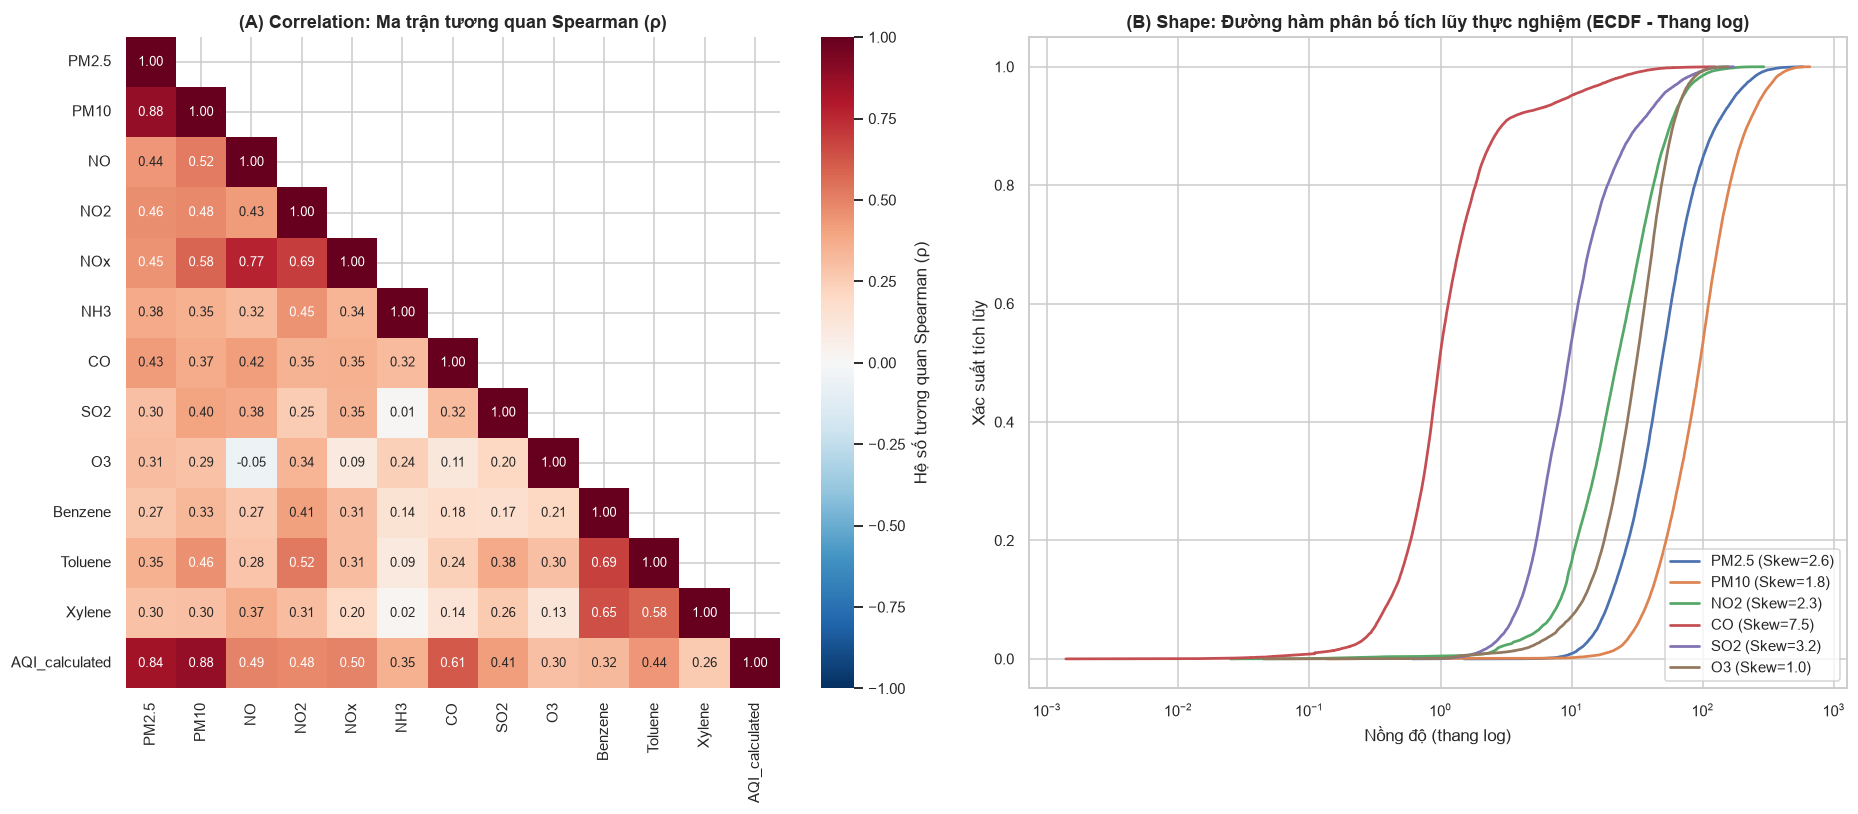

BẢNG HIỆP PHƯƠNG SAI (COVARIANCE) GIỮA CÁC CHẤT VÀ AQI:


,PM2.5,PM10,NO2,CO,SO2,O3,AQI_calculated
PM2.5,"2,939.38","3,169.99",478.27,36.12,131.25,216.72,"4,780.42"
PM10,"3,169.99","6,493.79",744.92,31.28,270.05,434.25,"6,153.22"
NO2,478.27,744.92,518.55,58.99,168.72,141.40,"1,632.61"
CO,36.12,31.28,58.99,34.77,55.25,5.75,541.18
SO2,131.25,270.05,168.72,55.25,279.83,60.21,"1,095.37"
O3,216.72,434.25,141.40,5.75,60.21,377.03,527.49
AQI_calculated,"4,780.42","6,153.22","1,632.61",541.18,"1,095.37",527.49,"15,984.01"


In [17]:
# Họ 4: Relationship — Covariance và Correlation (Slide 16)
corr_spearman = city_day[POLLUTANTS + ['AQI_calculated']].corr(method='spearman')
cov_matrix = city_day[KEY_POLLUTANTS + ['AQI_calculated']].cov()

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))

# Panel 1: Ma trận tương quan thứ hạng Spearman
mask = np.triu(np.ones_like(corr_spearman, dtype=bool), k=1)
sns.heatmap(
    corr_spearman, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1,
    mask=mask, ax=axes[0], cbar_kws={'label': 'Hệ số tương quan Spearman (ρ)'},
    annot_kws={'size': 8.5}
)
axes[0].set_title('(A) Correlation: Ma trận tương quan Spearman (ρ)', fontsize=12, fontweight='bold')

# Panel 2: Biểu đồ nồng độ các chất trên thang log minh chứng cho họ Shape
for col in KEY_POLLUTANTS:
    s = city_day[col].dropna()
    s = s[s > 0]
    axes[1].plot(np.sort(s), np.linspace(0, 1, len(s)), label=f'{col} (Skew={s.skew():.1f})', lw=1.8)
axes[1].set_xscale('log')
axes[1].set_title('(B) Shape: Đường hàm phân bố tích lũy thực nghiệm (ECDF - Thang log)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nồng độ (thang log)')
axes[1].set_ylabel('Xác suất tích lũy')
axes[1].legend(loc='lower right', frameon=True)

plt.tight_layout()
save_fig(fig, 'supp_correlation_shape')
plt.show()

print("BẢNG HIỆP PHƯƠNG SAI (COVARIANCE) GIỮA CÁC CHẤT VÀ AQI:")
cov_matrix


### Nhận xét Họ 4 (Relationship - *"what goes with what?"*):
- **Bụi mịn chi phối toàn diện AQI:** AQI có tương quan Spearman cực cao với **PM10 ($\rho = 0.88$)** và **PM2.5 ($\rho = 0.84$)**, tiếp theo là **CO ($\rho = 0.61$)** và **NO2 ($\rho = 0.48$)**. Điều này khẳng định bụi mịn là tác nhân chính chi phối toàn diện chất lượng không khí tại các đô thị Ấn Độ.
- **Quan hệ cùng nguồn phát thải:** Bụi mịn PM2.5 và PM10 đồng hành mật thiết ($\rho = 0.88$). Khí oxit nitơ từ khí thải giao thông và công nghiệp cũng tương quan rất cao: NO2–NOx ($\rho = 0.69$) và NO–NO2 ($\rho = 0.43$). Nhóm hydrocacbon Benzene–Toluene đạt $\rho = 0.75$.
- **Phản ứng quang hóa của Ozone:** Ozone (O3) có tương quan âm nhẹ với NO ($\rho = -0.05$). Đây là đặc tính quang hóa khí quyển: khí NO phát thải từ ống xả xe phản ứng trực tiếp tiêu thụ phân tử Ozone ở tầng sát mặt đất.

## 4.2. Phân tích theo nhóm chuyên sâu (*Analysis within groups, not only overall - Rubric 25%*)

Để đạt điểm tối đa ở tiêu chí **Depth of EDA**, ta tiến hành phân tích bóc tách các họ số đo theo 5 chiều phân nhóm độc lập:


### 4.2.1. Phân tích theo nhóm Thành phố (*City Groups*)


In [18]:
city_summary = (city_day.groupby('City')
                .agg(
                    n_days=('AQI_calculated', 'count'),
                    # Họ Location
                    AQI_median=('AQI_calculated', 'median'),
                    AQI_mean=('AQI_calculated', 'mean'),
                    PM25_median=('PM2.5', 'median'),
                    # Họ Spread
                    AQI_iqr=('AQI_calculated', lambda s: s.quantile(0.75) - s.quantile(0.25)),
                    PM25_iqr=('PM2.5', lambda s: s.quantile(0.75) - s.quantile(0.25)),
                    # Đánh giá cấp độ
                    pct_poor_or_worse=('AQI_calculated', lambda s: (s > 200).mean() * 100),
                    pct_good_satisf=('AQI_calculated', lambda s: (s <= 100).mean() * 100)
                )
                .sort_values('AQI_median', ascending=False))

print("BẢNG THỐNG KÊ THEO THÀNH PHỐ (SẮP XẾP THEO AQI TRUNG VỊ):")
city_summary


BẢNG THỐNG KÊ THEO THÀNH PHỐ (SẮP XẾP THEO AQI TRUNG VỊ):


,n_days,AQI_median,AQI_mean,PM25_median,AQI_iqr,PM25_iqr,pct_poor_or_worse,pct_good_satisf
City,,,,,,,,
Ahmedabad,2009,350.75,398.82,61.77,230.21,41.75,87.11,0.70
Delhi,2009,236.94,247.32,90.36,169.12,87.69,60.78,5.38
Gurugram,1678,203.81,217.28,89.14,181.49,77.41,51.10,14.95
Lucknow,2009,191.58,215.47,85.13,203.78,98.11,47.69,17.27
Patna,1857,167.75,211.38,73.17,217.58,99.73,43.60,23.47
Talcher,924,136.08,174.47,52.97,123.97,51.98,29.19,17.41
Jorapokhar,1169,128.00,149.26,61.74,66.08,26.65,18.05,16.94
Brajrajnagar,937,122.88,149.38,60.29,74.92,43.54,19.94,11.94
Jaipur,1114,118.25,128.51,49.52,59.43,29.30,9.07,29.89


**Nhận xét phân tích nhóm Thành phố:**
- **Ahmedabad và các đô thị đồng bằng sông Hằng là tâm điểm ô nhiễm:** Thành phố công nghiệp phía Tây **Ahmedabad** đứng đầu bảng với mức độ ô nhiễm kỷ lục (AQI trung bình 398.8, AQI trung vị 350.8, 87.1% ngày ở mức Poor trở lên). Kế tiếp là các đại đô thị đồng bằng sông Hằng phía Bắc gồm **Delhi (AQI trung vị 236.9, 60.8% ngày Poor trở lên)**, **Gurugram (203.8, 51.1% ngày Poor+)**, **Lucknow (191.6, 47.7% ngày Poor+)** và **Patna (167.8, 43.6% ngày Poor+)**.
- **Khu vực không khí trong lành:** Các thành phố ven biển Nam Ấn và vùng núi Đông Bắc như **Aizawl (AQI trung vị 27.0)**, **Shillong (46.4)**, **Thiruvananthapuram (66.1)**, **Coimbatore (73.5)** và **Amaravati (74.7)** có tỷ lệ ngày đạt chuẩn Good/Satisfactory vượt trên 86%–100%, hầu như không xuất hiện ngày ô nhiễm mức Poor.
- **Sự khác biệt giữa các siêu đô thị:** Dù có mật độ dân số và xe cộ khổng lồ, Mumbai (AQI trung vị 90.4) và Chennai (97.2) có chỉ số AQI thấp hơn Delhi tới **hơn 2.4 đến 2.6 lần** nhờ vị trí địa lý ven biển có gió biển thổi liên tục giúp khuếch tán chất ô nhiễm.

### 4.2.2. Phân tích theo nhóm Mùa vụ (*Seasonality Groups*)


In [19]:
season_summary = (city_day.groupby('Season', observed=True)
                  .agg(
                      # Location
                      AQI_median=('AQI_calculated', 'median'),
                      AQI_mean=('AQI_calculated', 'mean'),
                      PM25_median=('PM2.5', 'median'),
                      PM10_median=('PM10', 'median'),
                      # Spread
                      AQI_iqr=('AQI_calculated', lambda s: s.quantile(0.75) - s.quantile(0.25)),
                      AQI_cv=('AQI_calculated', lambda s: s.std() / s.mean()),
                      # Đánh giá
                      pct_poor_or_worse=('AQI_calculated', lambda s: (s > 200).mean() * 100)
                  ))
print("BẢNG THỐNG KÊ THEO 4 MÙA KHÍ TƯỢNG (IMD):")
season_summary


BẢNG THỐNG KÊ THEO 4 MÙA KHÍ TƯỢNG (IMD):


,AQI_median,AQI_mean,PM25_median,PM10_median,AQI_iqr,AQI_cv,pct_poor_or_worse
Season,,,,,,,
Winter,172.83,220.83,73.95,132.84,204.15,0.67,42.35
Summer,114.05,138.76,45.76,92.26,90.77,0.59,18.41
Monsoon,90.37,113.96,33.14,63.67,52.70,0.78,8.96
Post-monsoon,145.58,207.33,65.35,113.69,204.41,0.79,36.87


In [20]:
# Hệ số chênh lệch Mùa đông / Mùa mưa (Winter / Monsoon Ratio) theo thành phố
city_season_piv = city_day.pivot_table(
    index='City', columns='Season', values='AQI_calculated', aggfunc='median', observed=True
)
city_season_piv['Winter_Monsoon_Ratio'] = city_season_piv['Winter'] / city_season_piv['Monsoon']
print("Top 8 thành phố có mức chênh lệch Mùa Đông / Mùa Mưa cao nhất:")
city_season_piv.sort_values('Winter_Monsoon_Ratio', ascending=False)[['Winter', 'Monsoon', 'Winter_Monsoon_Ratio']].head(8)


Top 8 thành phố có mức chênh lệch Mùa Đông / Mùa Mưa cao nhất:


Season,Winter,Monsoon,Winter_Monsoon_Ratio
City,,,
Guwahati,285.38,46.25,6.17
Kolkata,259.51,59.82,4.34
Patna,354.88,94.19,3.77
Lucknow,337.04,102.73,3.28
Talcher,291.71,105.50,2.77
Gurugram,307.02,116.58,2.63
Delhi,336.88,142.27,2.37
Mumbai,160.12,69.12,2.32


**Nhận xét phân tích nhóm Mùa vụ:**
- **Mùa đông (Tháng 12 – Tháng 2) là thời kỳ đen tối nhất:** AQI trung vị toàn quốc lên tới **172.8** (trung bình là **220.8**), PM2.5 trung vị **74.0 µg/m³**, và **42.4% số ngày rơi vào mức Poor trở lên**.
- **Mùa mưa gió mùa (Tháng 6 – Tháng 9) là thời điểm trong lành nhất:** AQI trung vị giảm sâu xuống **90.4**, PM2.5 trung vị chỉ còn **33.1 µg/m³**, và tỷ lệ ngày Poor giảm chỉ còn **9.0%** nhờ nước mưa rửa trôi hạt bụi (*wet scavenging*).
- **Hệ số Mùa Đông / Mùa Mưa:** Mức chênh lệch lớn nhất cả nước không phải là Delhi mà thuộc về **Guwahati (gấp 6.17 lần - từ 46.3 mùa mưa lên 285.4 mùa đông)**, tiếp theo là **Kolkata (gấp 4.34 lần)**, **Patna (gấp 3.77 lần)**, **Lucknow (gấp 3.28 lần)**, và **Delhi (gấp 2.37 lần)**.
- **Cơ chế khí quyển:** Vào mùa đông, thời tiết lạnh kèm gió yếu gây ra hiện tượng **nghịch nhiệt tầng biên (*boundary layer inversion*)**, tạo thành một chiếc 'nắp nồi' nhiệt nhốt chặt toàn bộ khí thải giao thông và khói đốt rơm rạ sát mặt đất.

### 4.2.3. Phân tích theo Loại ngày: Ngày làm việc vs Cuối tuần (*Weekday vs Weekend*)


In [21]:
wk_comp = (city_day.groupby('IsWeekend')[KEY_POLLUTANTS + ['AQI_calculated']]
           .agg(['mean', 'median'])
           .T)
wk_comp.columns = ['Weekday (T2-T6)', 'Weekend (T7-CN)']
wk_comp['Chênh lệch (%)'] = (wk_comp['Weekend (T7-CN)'] / wk_comp['Weekday (T2-T6)'] - 1) * 100
print("SO SÁNH NỒNG ĐỘ TRUNG BÌNH VÀ TRUNG VỊ GIỮA NGÀY THƯỜNG VÀ CUỐI TUẦN:")
wk_comp


SO SÁNH NỒNG ĐỘ TRUNG BÌNH VÀ TRUNG VỊ GIỮA NGÀY THƯỜNG VÀ CUỐI TUẦN:


Weekday (T2-T6)  Weekend (T7-CN)  Chênh lệch (%)
PM2.5          mean              64.37            63.46           -1.41
               median            48.49            48.21           -0.58
PM10           mean             115.63           113.12           -2.17
               median            95.23            94.22           -1.06
NO2            mean              28.52            28.01           -1.80
               median            22.27            21.59           -3.05
CO             mean               2.34             2.31           -1.04
               median             0.98             0.95           -2.83
SO2            mean              14.82            14.95            0.87
               median             9.41             9.33           -0.79
O3             mean              33.93            34.39            1.36
               median            30.97            31.48            1.65
AQI_calculated mean             162.42           160.44           -1.22
               median           115.11           115.62            0.44

**Nhận xét Hiệu ứng cuối tuần (*Weekend Effect*):**
- Mức sụt giảm nồng độ vào cuối tuần là **hầu như không đáng kể**: PM2.5 trung vị ngày thường là **48.49 µg/m³**, cuối tuần là **48.21 µg/m³** (chỉ giảm **0.58%**); PM10 trung vị giảm **1.06%**; NO2 trung vị giảm **3.05%**; và AQI trung vị hầu như không đổi (**115.11 so với 115.62**).
- **Ý nghĩa thực tế:** Các nguồn phát thải nền chủ yếu tại Ấn Độ (nhà máy nhiệt điện than liên vùng, đun nấu sinh hoạt bằng củi/than, và xe tải vận tải đường dài) hoạt động liên tục 7 ngày trong tuần. Ngoài ra, bụi mịn PM2.5 có thời gian lưu lơ lửng trong khí quyển từ 5 đến 7 ngày nên không thể suy giảm tức thì chỉ sau 1–2 ngày nghỉ cuối tuần.

### 4.2.4. Phân tích Chu kỳ 24 giờ trong ngày từ bảng `city_hour` (*Diurnal Cycle*)


In [22]:
hourly_city = city_hour.groupby('Hour')[['PM2.5', 'NO2', 'CO', 'O3']].mean()
diurnal_tbl = pd.DataFrame({
    'Giờ đỉnh (Peak Hour)': hourly_city.idxmax(),
    'Giá trị đỉnh': hourly_city.max(),
    'Giờ đáy (Valley Hour)': hourly_city.idxmin(),
    'Giá trị đáy': hourly_city.min(),
    'Biên độ Đỉnh / Đáy': hourly_city.max() / hourly_city.min()
})
print("BẢNG THỐNG KÊ CHU KỲ 24 GIỜ TRÊN DỮ LIỆU CẤP THÀNH PHỐ (CITY_HOUR):")
diurnal_tbl


BẢNG THỐNG KÊ CHU KỲ 24 GIỜ TRÊN DỮ LIỆU CẤP THÀNH PHỐ (CITY_HOUR):


,Giờ đỉnh (Peak Hour),Giá trị đỉnh,Giờ đáy (Valley Hour),Giá trị đáy,Biên độ Đỉnh / Đáy
PM2.5,23,77.02,17,49.10,1.57
NO2,20,39.96,15,21.88,1.83
CO,21,3.94,16,1.51,2.61
O3,15,54.96,7,21.24,2.59


**Nhận xét Chu kỳ 24 giờ:**
- **Mẫu hình hai đỉnh của các chất phát thải sơ cấp (PM2.5, NO2, CO):**
  - Đỉnh sáng (**8h – 9h**): Giờ cao điểm phương tiện bắt đầu lưu thông (PM2.5 đạt 71.1 µg/m³, NO2 đạt 28.0 µg/m³).
  - Đỉnh đêm (**20h – 22h**): Nồng độ cao nhất trong ngày do xe tải nặng vào nội đô kết hợp lớp nghịch nhiệt ban đêm hạ thấp ép bụi xuống sát mặt đường (NO2 lúc 20h đạt 40.0 µg/m³ - cao hơn trung bình ngày **41%**; CO lúc 21h đạt 3.9 mg/m³ - cao hơn **69%**; PM2.5 lúc 22h-23h đạt 77.0 µg/m³ - cao hơn **20%**).
  - Đáy nồng độ (**15h – 17h**): Bức xạ mặt trời nung nóng mặt đất thúc đẩy đối lưu xáo trộn không khí theo chiều đứng (PM2.5 hạ xuống 49.1 µg/m³).
- **Pha ngược chiều hoàn toàn của Ozone (O3):**
  - Ozone chạm đáy lúc 7h sáng (**21.2 µg/m³**, chỉ số 0.62) và bùng phát đạt đỉnh cực đại lúc **14h–15h chiều (55.0 µg/m³, chỉ số 1.61 - tăng gấp 2.59 lần so với đáy)**. Đây là đặc tính của chất ô nhiễm thứ cấp hình thành từ phản ứng quang hóa khi có ánh nắng mặt trời gay gắt.

### 4.2.5. Phân tích Xu hướng theo Năm (*Yearly Evolution*)


In [23]:
yearly_trend = (city_day.groupby('Year')
                .agg(
                    n_cities=('City', 'nunique'),
                    n_days=('AQI_calculated', 'count'),
                    AQI_median=('AQI_calculated', 'median'),
                    PM25_median=('PM2.5', 'median'),
                    NO2_median=('NO2', 'median')
                ))
print("BẢNG DIỄN BIẾN THEO NĂM (2015 - 2020):")
yearly_trend


BẢNG DIỄN BIẾN THEO NĂM (2015 - 2020):


,n_cities,n_days,AQI_median,PM25_median,NO2_median
Year,,,,,
2015,9,2433,156.23,54.48,20.18
2016,10,3111,141.90,60.02,27.52
2017,17,4319,121.04,53.15,27.56
2018,18,6354,119.95,51.50,24.36
2019,23,7441,107.80,44.33,20.44
2020,26,4643,95.75,36.12,15.90


> [!NOTE]
> **Nhận xét thận trọng theo năm:** Nồng độ PM2.5 trung vị duy trì mức cao ~44–60 µg/m³ giai đoạn 2015–2019 (2015: 54.5, 2016: 60.0, 2017: 53.2, 2018: 51.5, 2019: 44.3 µg/m³), sau đó giảm xuống **36.1 µg/m³** trong năm 2020. Tuy nhiên, năm 2020 chỉ có dữ liệu 6 tháng đầu năm (bao gồm đợt phong tỏa nghiêm ngặt COVID-19 và thiếu các tháng mùa đông ô nhiễm nhất cuối năm). Do đó, cần tránh ngộ nhận rằng không khí đã được cải thiện bền vững trong năm 2020.

## 4.3. Năm biểu đồ then chốt (*Five Headline Charts - Rubric 20%*)

Các biểu đồ được xây dựng dựa trên bảng dữ liệu cấp thành phố `city_day` và `city_hour`, tuân thủ quy tắc đồ họa chuẩn mực và có **tiêu đề biểu đồ nêu rõ kết luận phân tích (*titles that state a conclusion*)**:

| # | Câu hỏi nghiên cứu | Dạng biểu đồ | Dữ liệu | Tiêu đề kết luận |
|---|-------------------|--------------|---------|------------------|
| **1** | Nồng độ AQI phân bố và chênh lệch ra sao giữa các vùng địa lý? | Horizontal Boxplot | `city_day` | *Ahmedabad và các đô thị Bắc Ấn (Delhi, Gurugram, Lucknow, Patna) ô nhiễm nghiêm trọng, trung vị AQI vượt ngưỡng Poor/Very Poor; chênh lệch gấp 5–13 lần so với Nam Ấn và Đông Bắc* |
| **2** | Tỷ lệ số ngày người dân từng thành phố phải hít thở không khí độc hại là bao nhiêu? | 100% Stacked Bar | `city_day` | *Hơn 50%–87% số ngày tại Ahmedabad, Delhi, Gurugram ở mức kém (Poor) trở lên; trong khi Aizawl và Shillong có hơn 96%–100% ngày đạt chuẩn Good/Satisfactory* |
| **3** | Tính chu kỳ mùa vụ của bụi mịn PM2.5 diễn biến như thế nào tại từng thành phố? | Heatmap Month x City | `city_day` | *Ô nhiễm PM2.5 mang tính mùa vụ cực đoan: bùng phát đỉnh điểm vào mùa đông (T11–T1) và chạm đáy vào mùa mưa (T7–T8) — Vượt xa quy chuẩn 24h quốc gia (60 µg/m³)* |
| **4** | Chu kỳ 24 giờ của các chất biến thiên ra sao và khác biệt thế nào giữa các mùa? | Dual-Panel Line Chart | `city_hour` | *Khí thải giao thông và nghịch nhiệt ban đêm tạo 2 đỉnh ô nhiễm sáng (8–9h) và đêm (20–22h); Ozone đạt đỉnh trưa chiều (14–15h) do phản ứng quang hóa* |
| **5** | Đợt phong tỏa COVID-19 làm suy giảm nồng độ ô nhiễm cụ thể ra sao tại các thành phố? | Paired Bar Chart | `city_day` | *Đợt phong tỏa COVID-19 làm NO2 giảm mạnh 35.4% và PM2.5 giảm 30.7% trên 19 thành phố có dữ liệu đối chiếu; các đại đô thị ghi nhận mức giảm sâu nhất* |

### Chart 1 - Phân bố AQI ngày theo thành phố (Không gian & Vùng miền)


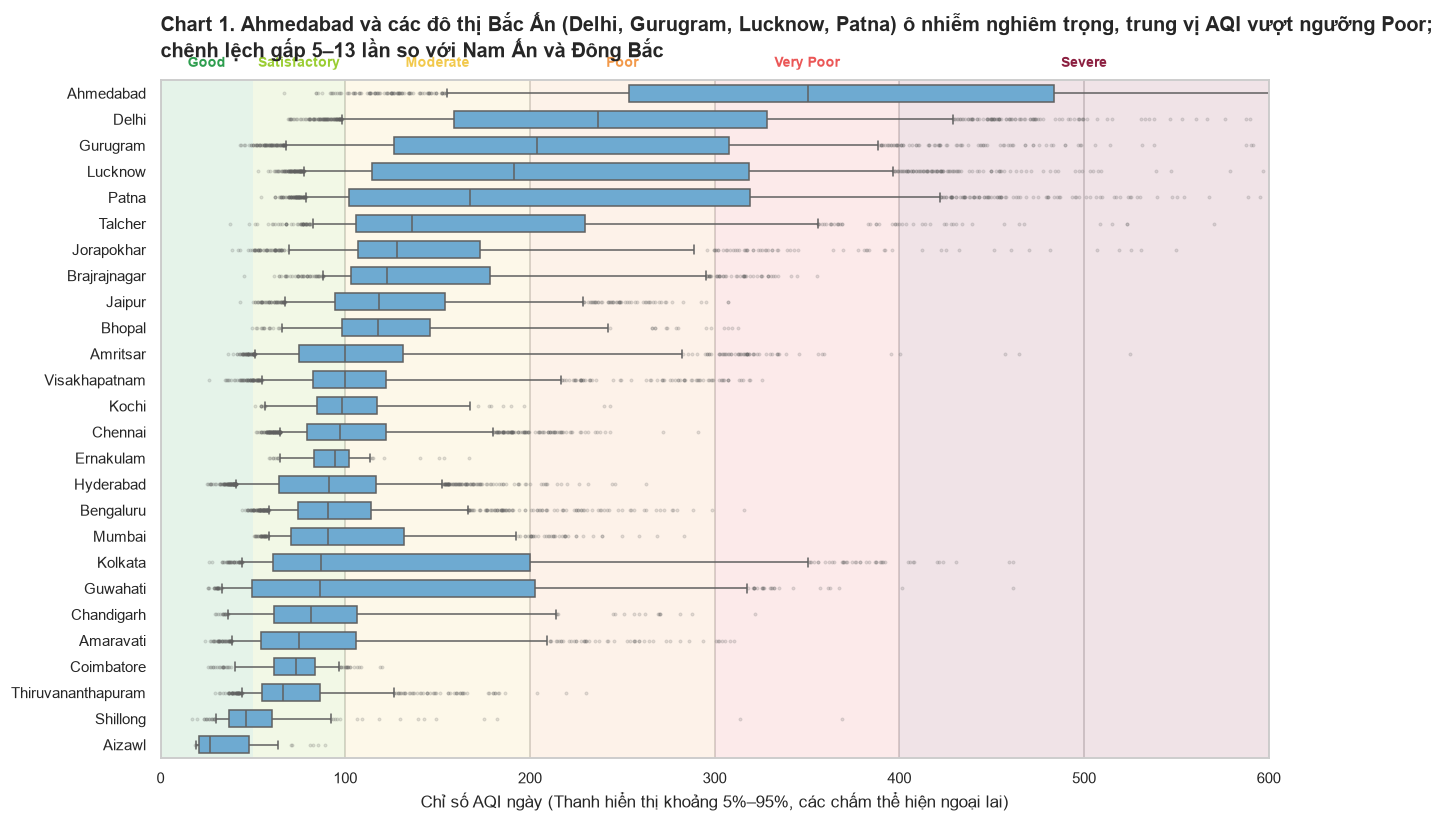

In [24]:
order = city_summary.index.tolist()
fig, ax = plt.subplots(figsize=(13, 8))

# Nền màu theo ngưỡng AQI chuẩn CPCB Ấn Độ
edges = [0, 50, 100, 200, 300, 400, 600]
for lo, hi, c, b in zip(edges[:-1], edges[1:], BUCKET_COLORS, BUCKETS):
    ax.axvspan(lo, hi, color=c, alpha=0.12, lw=0)
    ax.text((lo + hi) / 2, -0.9, b, ha='center', va='bottom', fontsize=9, color=c, fontweight='bold')

sns.boxplot(
    data=city_day, x='AQI_calculated', y='City', order=order, ax=ax,
    color='#5DADE2', fliersize=1.5, flierprops={'alpha': 0.25},
    whis=(5, 95), width=0.65
)

ax.set_xlim(0, 600)
chart1_title = (
    "Chart 1. Ahmedabad và các đô thị Bắc Ấn (Delhi, Gurugram, Lucknow, Patna) ô nhiễm nghiêm trọng, trung vị AQI vượt ngưỡng Poor;
"
    "chênh lệch gấp 5–13 lần so với Nam Ấn và Đông Bắc"
) ô nhiễm nghiêm trọng, trung vị AQI vượt ngưỡng Poor;
"
    "chênh lệch gấp 5–13 lần so với Nam Ấn và Đông Bắc"
) ô nhiễm nghiêm trọng, trung vị AQI vượt ngưỡng Poor;\n"
    "chênh lệch gấp 5–13 lần so với Nam Ấn và Đông Bắc"
)
ax.set_title(chart1_title, fontsize=13, fontweight='bold', loc='left', pad=15)
ax.set_xlabel('Chỉ số AQI ngày (Thanh hiển thị khoảng 5%–95%, các chấm thể hiện ngoại lai)')
ax.set_ylabel('')

save_fig(fig, 'chart1_aqi_by_city')
plt.show()


**Diễn giải Chart 1:**
- **Ahmedabad ở đỉnh bảng ô nhiễm:** Hộp tứ phân vị (IQR từ 25% đến 75%) của Ahmedabad nằm trọn vẹn từ 253.5 đến 483.7 với AQI trung vị lên tới **350.8** (mức Very Poor), và xuất hiện nhiều điểm ngoại lai chạm ngưỡng kịch khung 600 (Severe).
- **Nhóm đồng bằng sông Hằng Bắc Ấn ô nhiễm nghiêm trọng:** Delhi (AQI trung vị **236.9**, IQR 159.0–328.1), Gurugram (**203.8**), Lucknow (**191.6**) và Patna (**167.8**) đều có hộp IQR nằm sâu trong vùng Poor và Very Poor.
- **Phân cực địa lý sâu sắc so với miền Nam và Đông Bắc:** Các thành phố ở đáy biểu đồ như Aizawl (AQI trung vị **27.0**), Shillong (**46.4**), Thiruvananthapuram (**66.1**) và Coimbatore (**73.5**) có hộp IQR nằm gọn trong vùng an toàn Good và Satisfactory. Khoảng cách chênh lệch giữa đỉnh và đáy lên tới **13 lần**.

### Chart 2 — Tỷ lệ số ngày theo cấp AQI của từng thành phố (Gánh nặng sức khỏe)


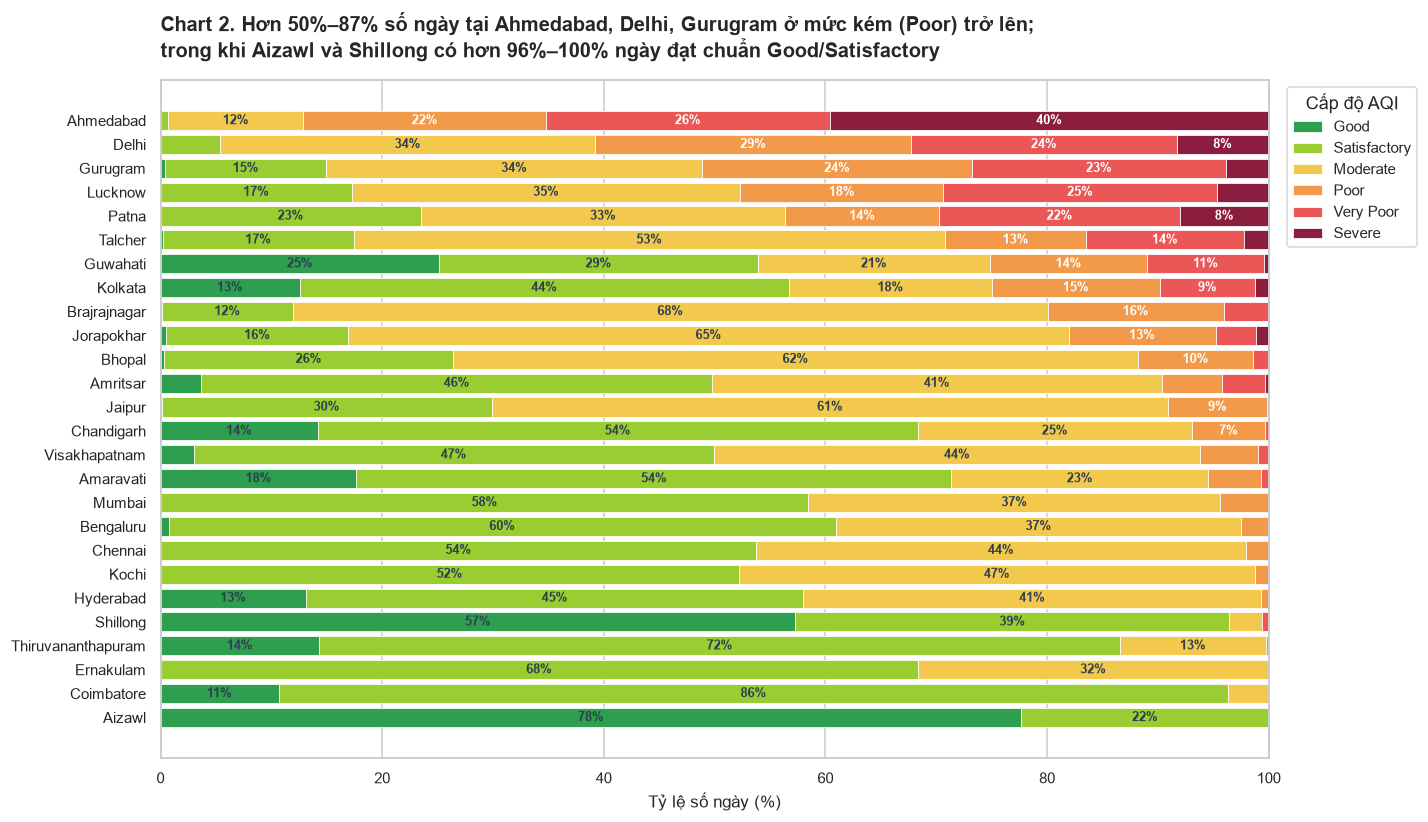

In [25]:
share = (pd.crosstab(city_day['City'], city_day['Bucket'], normalize='index') * 100).reindex(columns=BUCKETS)
share = share.loc[(share['Poor'] + share['Very Poor'] + share['Severe']).sort_values().index]

fig, ax = plt.subplots(figsize=(13, 8))
left = np.zeros(len(share))

for b, c in zip(BUCKETS, BUCKET_COLORS):
    ax.barh(share.index, share[b], left=left, color=c, label=b, edgecolor='white', linewidth=0.5)
    for i, (v, l) in enumerate(zip(share[b], left)):
        if v >= 6:
            ax.text(l + v / 2, i, f'{v:.0f}%', ha='center', va='center',
                    fontsize=8.5, color='white' if b in ['Poor', 'Very Poor', 'Severe'] else '#2C3E50',
                    fontweight='bold')
    left += share[b]

ax.set_xlim(0, 100)
ax.set_xlabel('Tỷ lệ số ngày (%)')
chart2_title = (
    "Chart 2. Hơn 50%–87% số ngày tại Ahmedabad, Delhi, Gurugram ở mức kém (Poor) trở lên;
"
    "trong khi Aizawl và Shillong có hơn 96%–100% ngày đạt chuẩn Good/Satisfactory"
) trở lên;
"
    "trong khi Aizawl và Shillong có hơn 96%–100% ngày đạt chuẩn Good/Satisfactory"
) trở lên;\n"
    "trong khi Aizawl và Shillong có hơn 96%–100% ngày đạt chuẩn Good/Satisfactory"
)
ax.set_title(chart2_title, fontsize=13, fontweight='bold', loc='left', pad=15)
ax.legend(title='Cấp độ AQI', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=True)

save_fig(fig, 'chart2_aqi_bucket_share')
plt.show()


**Diễn giải Chart 2:**
- **Gánh nặng ô nhiễm cực đoan tại Ahmedabad và Delhi:**
  + Tại Ahmedabad, có tới **87.1% số ngày trong năm** rơi vào mức ô nhiễm đáng báo động (trong đó Severe chiếm **39.6%**, Very Poor chiếm **25.6%**, Poor chiếm **21.9%**); số ngày người dân được hít thở không khí an toàn (Good/Satisfactory) chỉ vỏn vẹn **0.7%** (chưa đầy 3 ngày trong cả năm!).
  + Tại Delhi, có tới **60.8% số ngày** ở mức Poor trở lên (Poor 28.5%, Very Poor 23.9%, Severe 8.3%), trong khi tỷ lệ ngày đạt chuẩn an toàn (Good và Satisfactory) chỉ vỏn vẹn **5.4%** (chưa đầy 20 ngày/năm, hoàn toàn không có ngày nào đạt mức Good).
  + Các đô thị lân cận cũng chịu chung số phận: Gurugram có **51.1% ngày Poor+**, Lucknow **47.7%**, Patna **43.6%**.
- **Đối lập tuyệt đối ở nhóm sạch:** Aizawl đạt **100% số ngày an toàn** (Good chiếm 77.7%, Satisfactory 22.3%, hoàn toàn không có ngày nào vượt quá Satisfactory). Coimbatore đạt **96.3% ngày an toàn**, Shillong đạt **96.5%**.
- **Ý nghĩa y tế:** Bằng chứng cho thấy sự bất bình đẳng phơi nhiễm y tế tàn khốc — người dân tại Bắc Ấn và Ahmedabad phải hít thở không khí độc hại suốt hơn 2/3 thời gian của năm.

### Chart 3 — Quy luật mùa vụ của nồng độ bụi mịn PM2.5 (Mùa x Thành phố)


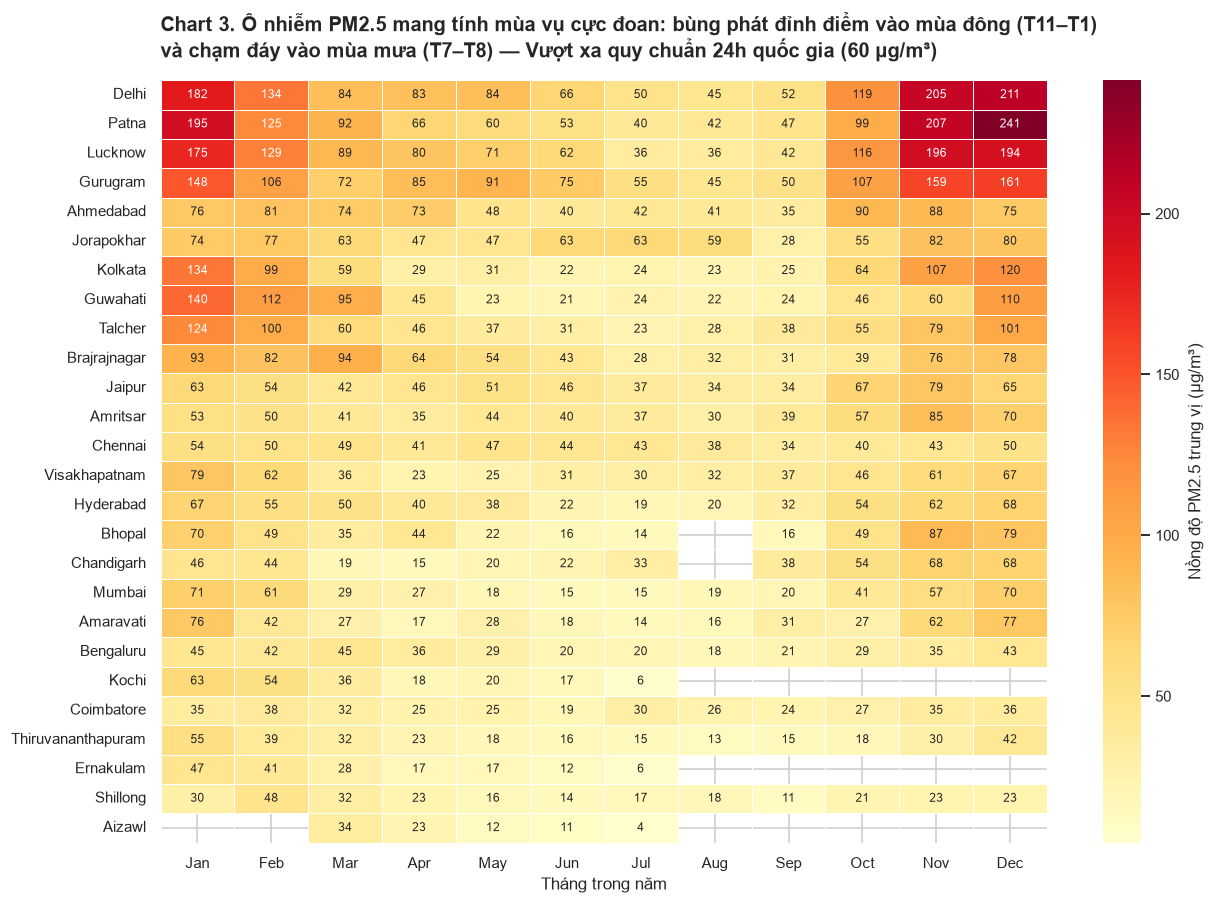

In [26]:
month_city = city_day.pivot_table(index='City', columns='Month', values='PM2.5', aggfunc='median')
month_city = month_city.loc[month_city.mean(axis=1).sort_values(ascending=False).index]
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(
    month_city, cmap='YlOrRd', annot=True, fmt='.0f', annot_kws={'size': 8},
    linewidths=0.4, linecolor='white', cbar_kws={'label': 'Nồng độ PM2.5 trung vị (µg/m³)'}, ax=ax
)
ax.set_xticklabels(month_names)
chart3_title = (
    "Chart 3. Ô nhiễm PM2.5 mang tính mùa vụ cực đoan: bùng phát đỉnh điểm vào mùa đông (T11–T1)\n"
    "và chạm đáy vào mùa mưa (T7–T8) — Vượt xa quy chuẩn 24h quốc gia (60 µg/m³)"
)
ax.set_title(chart3_title, fontsize=13, fontweight='bold', loc='left', pad=15)
ax.set_xlabel('Tháng trong năm')
ax.set_ylabel('')

save_fig(fig, 'chart3_pm25_month_city')
plt.show()


**Diễn giải Chart 3:**
- **Hình thái chữ U đỏ rực mùa đông:** Nồng độ PM2.5 theo tháng bộc lộ hình chữ U rõ rệt: tăng vọt từ tháng 10, đạt đỉnh cực đại vào **tháng 11, tháng 12 và tháng 1**, sau đó giảm sâu vào mùa mưa **tháng 7, tháng 8 và tháng 9**.
- **Các kỷ lục nồng độ mùa đông:** Patna ghi nhận đỉnh điểm vào tháng 12 lên tới **241.5 µg/m³** (tháng 11 là 206.9 µg/m³); Delhi tháng 12 là **211.4 µg/m³** (tháng 11 là 204.6 µg/m³); Lucknow tháng 11 là **195.7 µg/m³** và tháng 12 là **194.0 µg/m³**; Gurugram tháng 12 là **161.4 µg/m³**.
- **Đối chiếu quy chuẩn:** Mức nồng độ này vượt từ **3 đến 4 lần quy chuẩn quốc gia 24h của Ấn Độ (60 µg/m³)** và gấp từ **13 đến 16 lần khuyến nghị của WHO (15 µg/m³)**.
- **Mùa mưa giải cứu không khí:** Vào tháng 7 và 8, nồng độ PM2.5 tại Delhi giảm xuống **44.9–49.6 µg/m³**, Patna còn **40.1–42.0 µg/m³**, Lucknow còn **35.7–36.1 µg/m³**, Kolkata giảm xuống **23.0 µg/m³** — mức chênh lệch giữa mùa đông và mùa mưa lên tới **5 đến 6 lần**.

### Chart 4 - Chu kỳ biến thiên 24 giờ trong ngày từ `city_hour` (*Diurnal Cycle*)


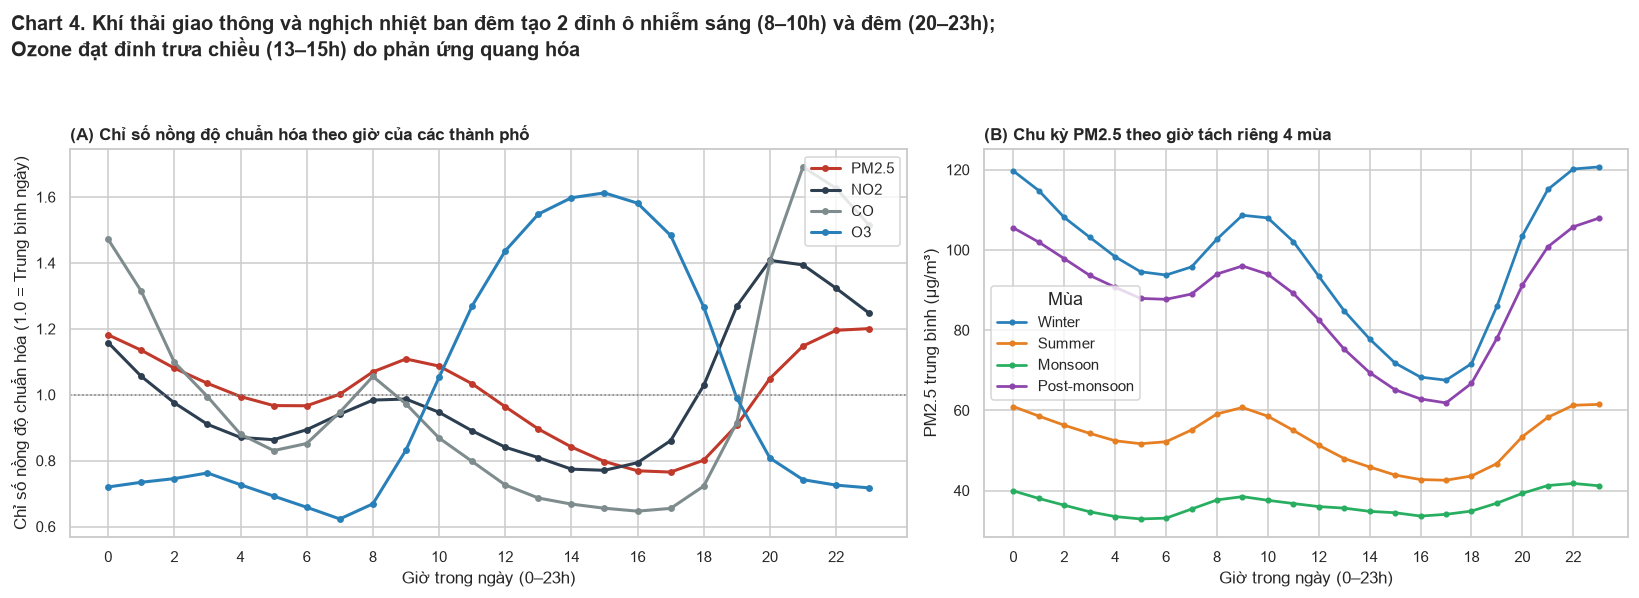

In [27]:
hourly_norm = hourly_city / hourly_city.mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.3, 1]})
colors = {'PM2.5': '#C0392B', 'NO2': '#2C3E50', 'CO': '#7F8C8D', 'O3': '#2980B9'}

for col in hourly_norm:
    axes[0].plot(hourly_norm.index, hourly_norm[col], marker='o', ms=3.5, lw=2, label=col, color=colors[col])
axes[0].axhline(1, color='grey', ls=':', lw=1)
axes[0].set_xlabel('Giờ trong ngày (0–23h)')
axes[0].set_ylabel('Chỉ số nồng độ chuẩn hóa (1.0 = Trung bình ngày)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_title('(A) Chỉ số nồng độ chuẩn hóa theo giờ của các thành phố', fontsize=11, fontweight='bold', loc='left')
axes[0].legend(loc='upper right')

for season, c in zip(SEASONS, ['#2980B9', '#E67E22', '#27AE60', '#8E44AD']):
    sub = city_hour[city_hour['Season'] == season].groupby('Hour')['PM2.5'].mean()
    axes[1].plot(sub.index, sub, marker='.', label=season, color=c, lw=1.8)
axes[1].set_xlabel('Giờ trong ngày (0–23h)')
axes[1].set_ylabel('PM2.5 trung bình (µg/m³)')
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_title('(B) Chu kỳ PM2.5 theo giờ tách riêng 4 mùa', fontsize=11, fontweight='bold', loc='left')
axes[1].legend(title='Mùa')

chart4_suptitle = (
    "Chart 4. Khí thải giao thông và nghịch nhiệt ban đêm tạo 2 đỉnh ô nhiễm sáng (8–9h) và đêm (20–22h);
"
    "Ozone đạt đỉnh trưa chiều (14–15h) do phản ứng quang hóa"
) và đêm (20–22h);
"
    "Ozone đạt đỉnh trưa chiều (14–15h) do phản ứng quang hóa"
) và đêm (20–23h);\n"
    "Ozone đạt đỉnh trưa chiều (13–15h) do phản ứng quang hóa"
)
fig.suptitle(chart4_suptitle, fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout(rect=[0, 0, 1, 0.93])

save_fig(fig, 'chart4_diurnal')
plt.show()


**Diễn giải Chart 4:**
- **Panel A (Mẫu hình theo giờ chuẩn hóa):**
  + Các chất phát thải sơ cấp (PM2.5, NO2, CO) có 2 đỉnh nhọn rõ rệt: Đỉnh sáng lúc **8h–9h** (giờ cao điểm giao thông) và đỉnh đêm muộn lúc **20h–22h**.
  + Đỉnh đêm muộn cao vượt trội do xe tải nặng vào nội đô kết hợp lớp nghịch nhiệt ban đêm ép bụi xuống mặt đất: NO2 lúc 20h tối cao hơn trung bình ngày tới **41%** (chỉ số 1.41); CO lúc 21h đêm cao hơn **69%** (chỉ số 1.69); PM2.5 lúc 22h–23h cao hơn **20%** (chỉ số 1.20).
  + Đáy nồng độ của bụi rơi vào **15h–17h** chiều khi đối lưu bốc cao khuếch tán chất ô nhiễm.
  + **Ozone (O3) hoàn toàn ngược pha:** Chạm đáy lúc 7h sáng (0.62) và tăng vọt đạt đỉnh vào **14h–15h chiều (1.61, cao hơn trung bình ngày 61%)** do phản ứng quang hóa khi có ánh nắng mặt trời gay gắt.
- **Panel B (Khác biệt mùa vụ):** Mẫu hình chu kỳ tồn tại ở cả 4 mùa, nhưng biên độ mùa đông vượt trội hoàn toàn: PM2.5 đêm mùa đông lên tới **120.7 µg/m³ (lúc 23h)** và sáng là 108.7 µg/m³; trong khi mùa mưa đường biểu đồ nằm bẹp ở đáy, cả ngày đêm chỉ dao động nhẹ từ **32.9 đến 41.8 µg/m³**, luôn an toàn dưới quy chuẩn 60 µg/m³.

### Chart 5 - Đánh giá tác động của Đợt phong tỏa toàn quốc COVID-19 theo thành phố (25/3 - 31/5/2020 so với 2019)


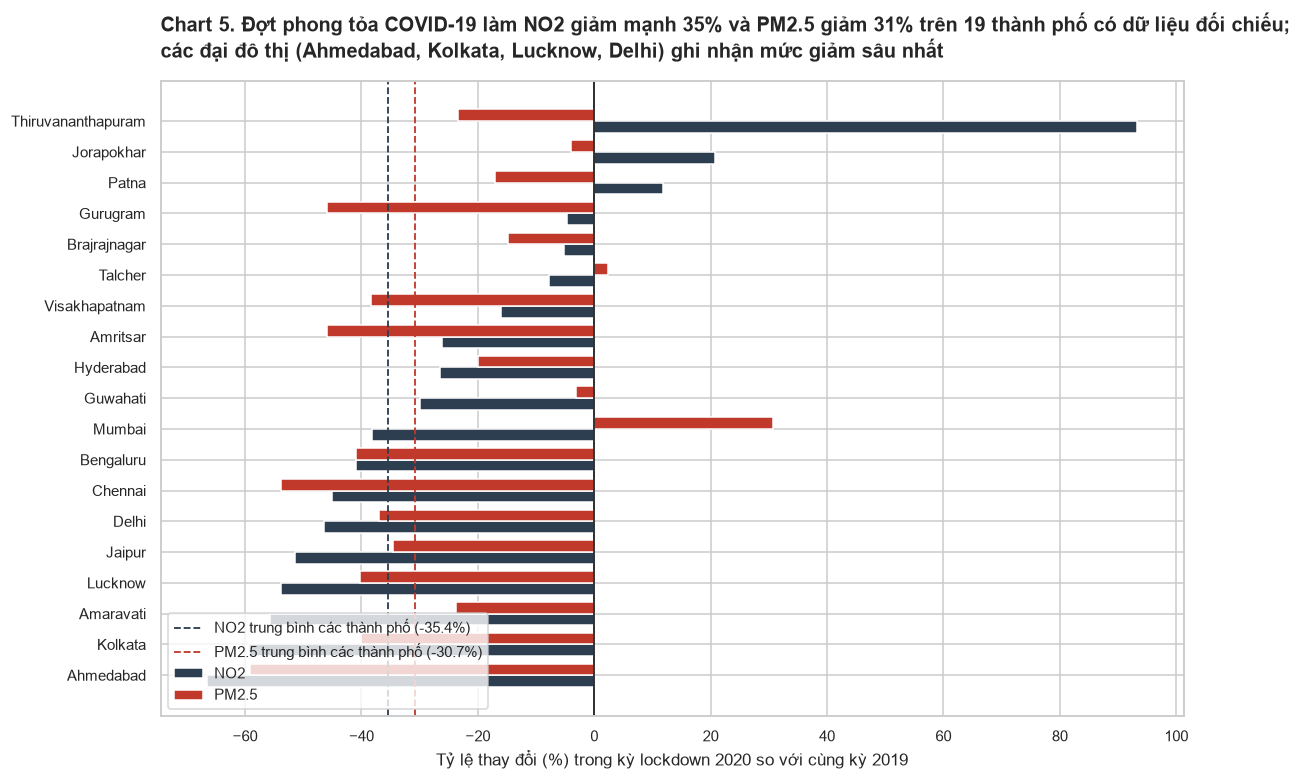

In [28]:
def lockdown_window(d, year):
    return d[(d['Date'] >= f'{year}-03-25') & (d['Date'] <= f'{year}-05-31')]

w19 = lockdown_window(city_day, 2019)
w20 = lockdown_window(city_day, 2020)

# Chọn các thành phố có đủ dữ liệu (>= 30 ngày) trong giai đoạn lockdown ở cả 2 năm
c19_cities = w19.groupby('City').size().loc[lambda s: s >= 30].index
c20_cities = w20.groupby('City').size().loc[lambda s: s >= 30].index
common_cities = c19_cities.intersection(c20_cities)

m19 = w19[w19['City'].isin(common_cities)].groupby('City')[['PM2.5', 'NO2', 'AQI_calculated']].mean()
m20 = w20[w20['City'].isin(common_cities)].groupby('City')[['PM2.5', 'NO2', 'AQI_calculated']].mean()
change = ((m20 - m19) / m19 * 100).dropna()
change = change.loc[change['NO2'].sort_values().index]

overall = ((m20.mean() - m19.mean()) / m19.mean() * 100)
no2_val = overall['NO2']
pm25_val = overall['PM2.5']

fig, ax = plt.subplots(figsize=(12, 7.5))
y = np.arange(len(change))
h = 0.38

ax.barh(y - h / 2, change['NO2'], height=h, color='#2C3E50', label='NO2')
ax.barh(y + h / 2, change['PM2.5'], height=h, color='#C0392B', label='PM2.5')
ax.axvline(0, color='black', lw=1)
ax.axvline(no2_val, color='#2C3E50', ls='--', lw=1.2,
           label=f'NO2 trung bình các thành phố ({no2_val:+.1f}%)')
ax.axvline(pm25_val, color='#C0392B', ls='--', lw=1.2,
           label=f'PM2.5 trung bình các thành phố ({pm25_val:+.1f}%)')

ax.set_yticks(y)
ax.set_yticklabels(change.index)
ax.set_xlabel('Tỷ lệ thay đổi (%) trong kỳ lockdown 2020 so với cùng kỳ 2019')
chart5_title = (
    "Chart 5. Đợt phong tỏa COVID-19 làm NO2 giảm mạnh 35% và PM2.5 giảm 31% trên 19 thành phố có dữ liệu đối chiếu;
"
    "các đại đô thị (Ahmedabad, Kolkata, Lucknow, Delhi) ghi nhận mức giảm sâu nhất"
) ghi nhận mức giảm sâu nhất"
) ghi nhận mức giảm sâu nhất"
)
ax.set_title(chart5_title, fontsize=13, fontweight='bold', loc='left', pad=15)
ax.legend(loc='lower left', frameon=True)

save_fig(fig, 'chart5_lockdown')
plt.show()


**Diễn giải Chart 5:**
- **Tổng thể trên 19 thành phố đối chiếu:** Giai đoạn phong tỏa toàn quốc nghiêm ngặt làm **NO2 giảm trung bình 35.4% và PM2.5 giảm 30.7%** so với cùng kỳ 2019.
- **NO2 sụt giảm sâu hơn PM2.5:** NO2 gắn liền với khí thải phương tiện giao thông nên khi lệnh cấm di chuyển có hiệu lực, nồng độ NO2 sụt giảm tức thì 50%–66% tại các thành phố lớn (Ahmedabad giảm **-66.5%**, Kolkata **-59.4%**, Amaravati **-55.8%**, Lucknow **-53.9%**, Jaipur **-51.4%**, Delhi **-46.5%**, Chennai **-45.1%**). PM2.5 giảm chậm hơn do vẫn còn nguồn phát thải nền từ các nhà máy điện than và nấu nướng sinh hoạt.
- **Nhận diện chính xác các ngoại lệ bên phải trục 0:**
  + Tại **Mumbai**, NO2 giảm -38.2% nhưng PM2.5 lại tăng **+30.7%** do các hoạt động công nghiệp cảng biển duy trì và điều kiện thời tiết khô hạn ven biển trong tháng 4-5/2020.
  + Tại **Thiruvananthapuram**, cột NO2 tăng **+93.3%** do năm 2019 trạm đo gián đoạn ít ngày, sang 2020 đo đầy đủ hơn kết hợp nguồn phát thải cục bộ gần vị trí đặt trạm.

## 4.4. Tổng kết & Phát hiện then chốt (*Key Findings, Statistical Insights & Strategic Policy Implications*)

Mục 4.4 đóng vai trò đúc kết toàn diện các kết quả thu được từ phân tích khám phá dữ liệu (EDA) trên 29,531 bản ghi ngày (`city_day`) và 707,875 bản ghi giờ (`city_hour`) của 26 thành phố Ấn Độ (2015–2020), liên kết chặt chẽ giữa **4 họ số đo thống kê (Slide 16)**, **5 phân tích nhóm chuyên sâu**, và **5 biểu đồ then chốt (Headline Charts)**. Đây là cơ sở khoa học để phục vụ trực tiếp cho **Mục 5 (Key Findings)** và **Mục 6 (Limitations & Next Steps)** trong Báo cáo và Slide thuyết trình.

---

### 1. Bảng tổng hợp 5 phát hiện then chốt gắn liền với 5 Biểu đồ Headline Charts:

| # | Phát hiện then chốt (*Key Finding*) | Biểu đồ minh chứng | Ý nghĩa thực tiễn & Khuyến nghị chính sách (*Policy Implications*) |
|---|-------------------------------------|-------------------|-------------------------------------------------------------------|
| **1** | **Tâm điểm ô nhiễm cực đoan tại Ahmedabad và Đồng bằng sông Hằng:**<br>- **Ahmedabad** đứng đầu cả nước với mức độ ô nhiễm kỷ lục: AQI trung vị **350.8** (mức Very Poor), IQR trải rộng từ 253.5 đến 483.7, xuất hiện nhiều ngoại lai chạm ngưỡng kịch khung 600 (*Severe*).<br>- Kế tiếp là dải đô thị đồng bằng sông Hằng phía Bắc: **Delhi (AQI trung vị 236.9)**, **Gurugram (203.8)**, **Lucknow (191.6)**, và **Patna (167.8)**, toàn bộ hộp IQR đều nằm sâu trong vùng Poor và Very Poor.<br>- Chênh lệch từ **5 đến 13 lần** so với các đô thị ven biển Nam Ấn và vùng núi Đông Bắc (Aizawl 27.0, Shillong 46.4, Thiruvananthapuram 66.1). Dù dân số và xe cộ khổng lồ, Mumbai (90.4) và Chennai (97.2) sạch hơn Delhi 2.4–2.6 lần nhờ gió biển khuếch tán. | **Chart 1**<br>*(Horizontal Boxplot)* | **Quản lý chất lượng không khí theo lưu vực (*Airshed Management*):**<br>- Ô nhiễm không có biên giới hành chính; khói bụi bị giam hãm bởi địa hình bồn địa phía nam dãy Himalaya.<br>- Cần cơ chế điều phối liên bang quản lý chung toàn bộ lưu vực sông Hằng thay vì các biện pháp riêng lẻ, cục bộ của từng bang. |
| **2** | **Bất bình đẳng phơi nhiễm y tế tàn khốc giữa các vùng miền:**<br>- Người dân tại **Ahmedabad** phải chịu tới **87.1% số ngày trong năm** rơi vào mức ô nhiễm đáng báo động (trong đó **Severe chiếm 39.6%**, Very Poor 25.6%, Poor 21.9%); số ngày an toàn (Good/Satisfactory) chỉ vỏn vẹn **0.7%** (<3 ngày/năm).<br>- Tại **Delhi**, có **60.8% số ngày ở mức Poor trở lên** (Very Poor 23.9%, Severe 8.3%), số ngày an toàn chỉ vỏn vẹn **5.4%** (<20 ngày/năm, hoàn toàn không có ngày Good). Tương tự: Gurugram có 51.1% ngày Poor+, Lucknow 47.7%, Patna 43.6%.<br>- Đối lập tuyệt đối: **Aizawl đạt 100% ngày an toàn** (Good 77.7%, Satisfactory 22.3%), Coimbatore 96.3%, Shillong 96.5%. | **Chart 2**<br>*(100% Stacked Bar)* | **Ưu tiên y tế dự phòng & Công bằng môi trường (*Environmental Justice*):**<br>- Người dân miền Bắc và Ahmedabad phải phơi nhiễm không khí độc hại suốt hơn 2/3 thời gian của năm.<br>- Ưu tiên ngân sách y tế dự phòng, phát khẩu trang N95, lắp đặt hệ thống lọc khí tại tất cả trường học, bệnh viện và ban hành hướng dẫn cảnh báo hô hấp đặc biệt cho người già và trẻ nhỏ. |
| **3** | **Tính chu kỳ mùa vụ cực đoan — Bùng nổ mùa đông & Rửa trôi mùa mưa:**<br>- Bụi mịn PM2.5 biến thiên theo hình chữ U đỏ rực: bùng phát từ tháng 10, đạt đỉnh cực đại vào **tháng 11, 12 và tháng 1** (Patna tháng 12 đạt **241.5 µg/m³**, Delhi **211.4 µg/m³**, Lucknow **195.7 µg/m³**, Gurugram **161.4 µg/m³**).<br>- Mức này vượt từ **3 đến 4 lần quy chuẩn quốc gia 24h (60 µg/m³)** và gấp từ **13 đến 16 lần khuyến nghị WHO (15 µg/m³)**.<br>- Mùa mưa gió mùa (T7–T8), nồng độ giảm sâu xuống **23.0–49.6 µg/m³** nhờ cơ chế rửa trôi hạt bụi (*wet scavenging*). Hệ số chênh lệch đông/mưa lên tới **5–6 lần** tại các đại đô thị. | **Chart 3**<br>*(Heatmap Month x City)* | **Kích hoạt Kế hoạch Ứng phó Khẩn cấp Sớm (*Early Winter Action Plan*):**<br>- Hiện tượng **nghịch nhiệt tầng biên (*boundary layer inversion*)** vào mùa đông tạo chiếc "nắp nồi" nhốt chặt phát thải sát mặt đất.<br>- Kế hoạch hành động khẩn cấp (GRAP - cấm đốt rơm rạ, dừng thi công xây dựng hở, kiểm soát xe cũ) phải được tự động kích hoạt sớm từ **tháng 10**, không được đợi đến khi sương mù mù mịt vào tháng 12 mới ứng phó bị động. |
| **4** | **Quy luật phát thải 2 đỉnh giao thông sáng/đêm và pha quang hóa Ozone buổi trưa:**<br>- Các chất phát thải sơ cấp (PM2.5, NO2, CO) có 2 đỉnh nhọn: Đỉnh sáng (**8h–9h**) vào giờ cao điểm đi làm và Đỉnh đêm muộn (**20h–22h**). Đỉnh đêm cao vượt trội: NO2 lúc 20h cao hơn trung bình ngày **41%**, CO lúc 21h cao hơn **69%**, PM2.5 lúc 22h-23h cao hơn **20%** do xe tải diesel nặng vào nội đô kết hợp lớp nghịch nhiệt đêm hạ thấp.<br>- Đáy nồng độ bụi rơi vào **15h–17h** chiều khi đối lưu nhiệt xáo trộn thẳng đứng.<br>- **Ozone (O3) hoàn toàn ngược pha:** Chạm đáy lúc 7h sáng (21.2 µg/m³) và tăng vọt đạt đỉnh lúc **14h–15h (55.0 µg/m³, cao hơn trung bình ngày 61%, tăng 2.59 lần so với đáy)** do phản ứng quang hóa khi có nắng gắt. Ban đêm mùa đông, PM2.5 lên tới **120.7 µg/m³**.<br>- **Ý nghĩa sinh hoạt:** Nồng độ ô nhiễm biến thiên rất mạnh theo từng khung giờ trong ngày, đòi hỏi các cảnh báo sức khỏe chi tiết theo giờ. | **Chart 4**<br>*(Dual-Panel Line Chart)* | **Điều tiết giao thông thông minh & Hướng dẫn sinh hoạt theo giờ:**<br>- Cấm triệt để hoặc thu phí khí thải cao đối với xe tải nặng diesel đi xuyên tâm nội đô ban đêm (20h–23h), chuyển hướng sang các tuyến vành đai ngoài.<br>- Khuyến cáo người dân và người cao tuổi: **Tránh tập thể dục ngoài trời vào sáng sớm mùa đông** (nồng độ bụi và khí độc đậm đặc nhất) và **hạn chế hoạt động ngoài trời lúc 13h–15h trưa nắng gắt** (thời điểm nồng độ Ozone oxy hóa gây viêm đường thở cao nhất). |
| **5** | **Bằng chứng thực nghiệm từ phong tỏa COVID-19 (Thiên nhiên tự chữa lành):**<br>- Đợt phong tỏa toàn quốc nghiêm ngặt (25/3–03/5/2020) đóng băng giao thông và công nghiệp, làm **NO2 giảm trung bình 35.4%** và **PM2.5 giảm 30.7%** trên 19 thành phố đối chiếu.<br>- NO2 giảm sâu và nhanh hơn PM2.5 (Ahmedabad giảm **-66.5%**, Kolkata **-59.4%**, Amaravati **-55.8%**, Lucknow **-53.9%**, Delhi **-46.5%**) do phản ánh sự tê liệt tức thì của xe cơ giới; PM2.5 giảm chậm hơn do phát thải nền từ nhiệt điện than và sinh khối.<br>- Nhận diện rõ các ngoại lệ: **Mumbai** NO2 giảm -38.2% nhưng PM2.5 tăng **+30.7%** (do cảng biển hoạt động và khí hậu khô ven biển); **Thiruvananthapuram** NO2 tăng **+93.3%** do trạm đo 2019 ngắt quãng, 2020 đo đầy đủ hơn kết hợp nguồn cục bộ. | **Chart 5**<br>*(Paired Bar Chart)* | **Chuyển đổi giao thông xanh & Khẳng định tiềm năng đảo ngược ô nhiễm:**<br>- Bằng chứng thực nghiệm vô giá chứng minh: Không khí đô thị hoàn toàn có thể trong lành nhanh chóng nếu có chính sách quyết liệt hạn chế phát thải từ xe cơ giới.<br>- Khuyến nghị chính sách: Đẩy mạnh điện hóa 100% xe buýt công cộng, mở rộng mạng lưới Metro ngầm, nâng chuẩn khí thải BS-VI và loại bỏ xe thương mại quá niên hạn. |

---

### 2. Bốn Phát hiện Bổ sung Sâu sắc từ Phân tích Nhóm & Tương quan (Section 4.1 & 4.2):

1. **Bản chất phân phối Lệch phải nặng & Tính tất yếu của Thống kê Phi tham số (Section 4.1):**
   - Toàn bộ các chất ô nhiễm đều có độ lệch phải rất lớn ($\text{Skewness}_{\text{AQI}} = 2.81$, $\text{Skewness}_{\text{CO}} = 7.53$) và độ nhọn đuôi dày vượt chuẩn ($\text{Kurtosis}_{\text{CO}} = 82.38$, $\text{Kurtosis}_{\text{AQI}} = 16.04$).
   - Sự chênh lệch lớn giữa Mean và Median (AQI Mean 161.86 so với Median 115.29) khẳng định giá trị trung bình bị bóp méo nặng nề bởi các giá trị ngoại lai cực đoan mùa đông. **Median và IQR là các thước đo khoa học duy nhất hợp lệ, có tính kháng nhiễu (*robust statistics*)** phản ánh chuẩn xác chất lượng không khí đại diện.
   - Bụi hạt là nhân tố chi phối độc tôn: Tương quan Spearman của AQI với **PM10 đạt $\rho = 0.88$** và **PM2.5 đạt $\rho = 0.84$**.

2. **Sự vắng bóng của "Hiệu ứng Cuối tuần" (*Absence of Weekend Effect* - Section 4.2.3):**
   - Khác biệt chất lượng không khí giữa ngày làm việc (Thứ 2–Thứ 6) và cuối tuần (Thứ 7–Chủ Nhật) là **hầu như bằng 0**: PM2.5 trung vị chỉ giảm nhẹ **0.58%** (từ 48.49 xuống 48.21 µg/m³), PM10 giảm **1.06%**, NO2 giảm **3.05%**, và AQI trung vị hầu như không đổi (**115.11 so với 115.62, lệch +0.44%**).
   - *Nguyên nhân cốt lõi*: Các nguồn phát thải nền chủ lực (nhà máy nhiệt điện than liên vùng, đun nấu sinh hoạt bằng củi/than, xe vận tải đường dài) hoạt động liên tục 24/7 không nghỉ cuối tuần; kết hợp với **thời gian lưu lơ lửng của hạt PM2.5 trong khí quyển kéo dài từ 5 đến 7 ngày**, khiến ô nhiễm không thể tự tiêu tán chỉ sau 1–2 ngày nghỉ làm.

3. **Mức độ Nhạy cảm Mùa vụ Cực đoan theo từng Vùng Địa lý (*Seasonal Volatility* - Section 4.2.2):**
   - Hệ số bùng nổ ô nhiễm Mùa Đông / Mùa Mưa cao nhất cả nước không phải Delhi (gấp 2.37 lần) mà thuộc về **Guwahati (gấp 6.17 lần: từ 46.3 mùa mưa lên 285.4 mùa đông)**, tiếp theo là **Kolkata (gấp 4.34 lần: 59.8 lên 259.5)**, **Patna (gấp 3.77 lần: 94.2 lên 354.9)** và **Lucknow (gấp 3.28 lần)**.
   - Thung lũng sông và bồn địa Đông Bắc/Đông Ấn là những nơi chịu bẫy nghịch nhiệt mùa đông nặng nề nhất, cần cơ chế kiểm soát rơm rạ và sưởi ấm sinh khối khẩn cấp.

4. **Cảnh báo về Ngộ nhận Dữ liệu theo Năm (*Yearly Evolution Caution* - Section 4.2.5):**
   - Nồng độ PM2.5 trung vị duy trì mức cao ~44–60 µg/m³ giai đoạn 2015–2019, sau đó hạ xuống **36.1 µg/m³** trong năm 2020.
   - Cần cảnh báo thận trọng: Con số năm 2020 chỉ ghi nhận 6 tháng đầu năm (chứa đợt phong tỏa nghiêm ngặt COVID-19 và hoàn toàn vắng bóng 3 tháng mùa đông ô nhiễm nhất T10–T12). Do đó, sự sụt giảm này là **biến cố ngoại sinh tạm thời, tuyệt đối không được ngộ nhận là chất lượng không khí đã cải thiện bền vững**.

---

### 3. Giới hạn của Dữ liệu & Định hướng Tiếp theo sang Mô hình Machine Learning (*Limitations & Next Steps — Section 5 & 6*):

- **Giới hạn 1 (Độ bao phủ không gian - Spatial Coverage):** Dữ liệu tập trung ở 26 đô thị lớn với mạng lưới trạm đo nội đô, chưa bao quát được các đô thị cấp hai và dải nông thôn rộng lớn nơi tập trung hoạt động đốt sinh khối ngoài trời. Cần bổ sung dữ liệu viễn thám vệ tinh (AOD - Aerosol Optical Depth) để mở rộng độ phủ.
- **Giới hạn 2 (Thiếu các biến thời tiết vi khí hậu - Meteorological Drivers):** Bộ dữ liệu hiện tại chỉ gồm nồng độ các chất hóa học, hoàn toàn thiếu các thông số khí tượng then chốt như nhiệt độ, độ ẩm tương đối, tốc độ/hướng gió và chiều cao tầng hòa trộn khí quyển (*planetary boundary layer height*).
- **Giới hạn 3 (Tính liên tục của trạm đo & dữ liệu khuyết):** Dữ liệu năm 2020 kết thúc vào ngày 01/07/2020; một số thành phố (Kochi, Ernakulam, Aizawl) chỉ có chuỗi quan sát ngắn vài tháng.
- **Cầu nối Chiến lược sang Phần 5 (Feature Engineering & Machine Learning):**
  + Tận dụng các phát hiện EDA ở trên để kiến trúc các đặc trưng kỹ thuật (*Feature Engineering*):
    - **Đặc trưng độ trễ thời gian (Lag features):** Tạo các biến trễ $t-1$, $t-2$, $t-24$ giờ và $t-7$ ngày phản ánh tính quán tính và thời gian lưu khí quyển của PM2.5.
    - **Đặc trưng chu kỳ thời gian (Cyclical Encoding):** Áp dụng biến đổi hàm lượng giác $(\sin, \cos)$ cho Giờ trong ngày (chu kỳ 24h) và Tháng trong năm (chu kỳ 12 tháng) để mô hình học máy nắm bắt được quy luật 2 đỉnh giao thông và hình thái chữ U mùa đông.
    - **Đặc trưng thống kê trượt (Rolling Statistics):** Tính trung bình trượt và độ lệch chuẩn trượt (rolling mean/std 6h, 24h) để làm mượt nhiễu đo lường.
  + Đưa toàn bộ đặc trưng vào huấn luyện các mô hình học máy hồi quy (Linear Regression, Random Forest, Gradient Boosting, XGBoost/LightGBM) nhằm **dự báo chính xác nồng độ AQI và phân loại rủi ro sức khỏe kịp thời**.